# Stage 2 experiment log (Dev only)

This section is the evidence for the Stage 2 comparisons quoted in the report that are not part of the final Stage 2 run above:
- the Stage 1 recipe retrained on the same machine (R),
- Role C's proposals C1 (class-weighted intent loss) and C2 (longer training),
- the per-class diagnostics, and
- the design sensitivity sweep (BiLSTM depth and width, character CNN and word dropout).

The saved Dev result files of every run were embedded by `scripts/d_build_experiment_log.py`, with their SHA-256 hashes. The cells below check the hashes and compute every table, rule outcome and figure from those files. Nothing is retrained here and **Test is never read**; Test was evaluated once, in the final Stage 2 cell above.

In [1]:
import csv, hashlib, io, json, statistics
import matplotlib.pyplot as plt

SEEDS = (42, 43, 44)
CORE_RUNS = {'R': ['results/stage2/d_stage1_ref_s42', 'results/stage2/d_stage1_ref_s43', 'results/stage2/d_stage1_ref_s44'], 'C1': ['results/stage2/d_intentcw_s42', 'results/stage2/d_intentcw_s43', 'results/stage2/d_intentcw_s44'], 'C2': ['results/stage2/d_intentcw_long_s42']}
SWEEP_RUNS = {'layers2': ['results/sweep/d_sweep_layers2_s42', 'results/sweep/d_sweep_layers2_s43', 'results/sweep/d_sweep_layers2_s44'], 'layers3': ['results/sweep/d_sweep_layers3_s42', 'results/sweep/d_sweep_layers3_s43', 'results/sweep/d_sweep_layers3_s44'], 'hidden64': ['results/sweep/d_sweep_hidden64_s42', 'results/sweep/d_sweep_hidden64_s43', 'results/sweep/d_sweep_hidden64_s44'], 'hidden256': ['results/sweep/d_sweep_hidden256_s42', 'results/sweep/d_sweep_hidden256_s43', 'results/sweep/d_sweep_hidden256_s44'], 'nochar': ['results/sweep/d_abl_nochar_s42', 'results/sweep/d_abl_nochar_s43', 'results/sweep/d_abl_nochar_s44'], 'nowd': ['results/sweep/d_abl_nowd_s42', 'results/sweep/d_abl_nowd_s43', 'results/sweep/d_abl_nowd_s44'], 'neither': ['results/sweep/d_abl_neither_s42', 'results/sweep/d_abl_neither_s43', 'results/sweep/d_abl_neither_s44']}
SWEEP_READY = False
EMBEDDED = json.loads(r"""{"built_at_utc": "2026-11-09 11:58", "files": {"results/role_d/c_analysis.json": {"sha256": "dcf008f6a1baaaab08e688655127a1312cb5021b2caf5eb664c9d5f6ea964d12", "text": "{\n  \"note\": \"Dev only; Test never read. Rules in docs/D_STAGE2_PLAN.md.\",\n  \"configs\": {\n    \"R\": \"d_stage1_ref\",\n    \"C1\": \"d_intentcw\",\n    \"C2\": \"d_intentcw_long\"\n  },\n  \"runs\": {\n    \"R\": {\n      \"42\": {\n        \"run\": \"d_stage1_ref_s42\",\n        \"intent_accuracy_pct\": 86.8666994589277,\n        \"slot_micro_f1_pct\": 80.16194331983806,\n        \"selection_score\": 83.51432138938287,\n        \"best_epoch\": 38,\n        \"epochs_run\": 46,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 86.23853211009174\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 85.91184096802074\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 54.83870967741936,\n          \"qa_factoid\": 72.82608695652173\n        }\n      },\n      \"43\": {\n        \"run\": \"d_stage1_ref_s43\",\n        \"intent_accuracy_pct\": 87.11264141662568,\n        \"slot_micro_f1_pct\": 80.8167380892362,\n        \"selection_score\": 83.96468975293094,\n        \"best_epoch\": 36,\n        \"epochs_run\": 44,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 87.1559633027523\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 86.4304235090752\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 56.994818652849744,\n          \"qa_factoid\": 76.92307692307693\n        }\n      },\n      \"44\": {\n        \"run\": \"d_stage1_ref_s44\",\n        \"intent_accuracy_pct\": 87.55533694048205,\n        \"slot_micro_f1_pct\": 81.223148850139,\n        \"selection_score\": 84.38924289531053,\n        \"best_epoch\": 37,\n        \"epochs_run\": 45,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 86.23853211009174\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 86.25756266205704\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 59.25925925925925,\n          \"qa_factoid\": 74.72527472527473\n        }\n      }\n    },\n    \"C1\": {\n      \"42\": {\n        \"run\": \"d_intentcw_s42\",\n        \"intent_accuracy_pct\": 86.7683226758485,\n        \"slot_micro_f1_pct\": 81.80904522613065,\n        \"selection_score\": 84.28868395098957,\n        \"best_epoch\": 49,\n        \"epochs_run\": 57,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 88.9908256880734\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.70181503889368\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 51.764705882352935,\n          \"qa_factoid\": 74.44444444444444\n        }\n      },\n      \"43\": {\n        \"run\": \"d_intentcw_s43\",\n        \"intent_accuracy_pct\": 86.37481554353172,\n        \"slot_micro_f1_pct\": 80.16173869092746,\n        \"selection_score\": 83.26827711722959,\n        \"best_epoch\": 33,\n        \"epochs_run\": 41,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 91.74311926605505\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.96110630942091\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 49.43820224719101,\n          \"qa_factoid\": 73.40425531914893\n        }\n      },\n      \"44\": {\n        \"run\": \"d_intentcw_s44\",\n        \"intent_accuracy_pct\": 87.06345302508608,\n        \"slot_micro_f1_pct\": 81.60080543669771,\n        \"selection_score\": 84.3321292308919,\n        \"best_epoch\": 43,\n        \"epochs_run\": 51,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 88.07339449541284\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.87467588591184\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 56.353591160220994,\n          \"qa_factoid\": 72.52747252747253\n        }\n      }\n    },\n    \"C2\": {\n      \"42\": {\n        \"run\": \"d_intentcw_long_s42\",\n        \"intent_accuracy_pct\": 86.7683226758485,\n        \"slot_micro_f1_pct\": 81.80904522613065,\n        \"selection_score\": 84.28868395098957,\n        \"best_epoch\": 49,\n        \"epochs_run\": 61,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 88.9908256880734\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.70181503889368\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 51.764705882352935,\n          \"qa_factoid\": 74.44444444444444\n        }\n      }\n    }\n  },\n  \"three_seed_means\": {\n    \"R\": {\n      \"intent_accuracy_pct\": {\n        \"mean\": 87.17822593867848,\n        \"sample_sd\": 0.34897190775197146\n      },\n      \"slot_micro_f1_pct\": {\n        \"mean\": 80.73394341973776,\n        \"sample_sd\": 0.5354255432441952\n      },\n      \"selection_score\": {\n        \"mean\": 83.95608467920812,\n        \"sample_sd\": 0.43752422316257217\n      }\n    },\n    \"C1\": {\n      \"intent_accuracy_pct\": {\n        \"mean\": 86.7355304148221,\n        \"sample_sd\": 0.34548790794729356\n      },\n      \"slot_micro_f1_pct\": {\n        \"mean\": 81.19052978458528,\n        \"sample_sd\": 0.8970224569474249\n      },\n      \"selection_score\": {\n        \"mean\": 83.96303009970369,\n        \"sample_sd\": 0.6020657381706216\n      }\n    }\n  },\n  \"rules\": {\n    \"rule1_c1_gate\": 83.51432138938287,\n    \"rule1_c1_passes\": true,\n    \"rule2_c2_gate\": 84.28868395098957,\n    \"rule2_c2_passes\": false,\n    \"stage2_configuration\": \"C1\",\n    \"stage2_run\": \"d_intentcw_s42\",\n    \"rule5_mean_vs_reference_pp\": 0.00694542049556901\n  }\n}\n"}, "results/stage2/d_stage1_ref_s42/summary.json": {"sha256": "0ded1b93af48fb4b9b7e4489d3c233a67ec5beba073450e9ed2873c3446d9351", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 38,\n  \"epochs_run\": 46,\n  \"selection_score\": 83.51432138938287,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.8666994589277,\n    \"slot_micro_f1_pct\": 80.16194331983806,\n    \"slot_tp\": 1584,\n    \"slot_fp\": 356,\n    \"slot_fn\": 428\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_stage1_ref_s42.pt\",\n  \"checkpoint_sha256\": \"514a1bf58ee9f1b75277bbc6f6c8c6acc2e5cad472e94addcb94a5df6aa9c6f0\",\n  \"elapsed_seconds\": 4279.2837401,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_stage1_ref_s42/history.csv": {"sha256": "1e5ebf271dbb7183bdbd478c0d618ef80c158f31bcdb2833cc9c1a5cf2cea1a8", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.373161619277108,3.4452725003447737,0.9639445594661672,3.4284638780976087,2.308630264514899,0.559916806791355,44.71224790949336,21.060782036391792,272,299,1740,32.88651497294258,0.001,80.42153999999573,84.04972729999281\n2,2.894635940762821,1.8899360664689708,0.5023499371469251,1.8769944191724277,1.1603483189753108,0.3583230500985585,69.01131333005411,53.51089588377724,884,408,1128,61.26110460691567,0.001,99.19054680000409,183.3078356999904\n3,2.000686790666089,1.2259967310966584,0.3873450297847153,1.4266801463060954,0.8403027971214223,0.29318867459233655,77.76684702410232,62.774566473988436,1086,362,926,70.27070674904537,0.001,82.21394909999799,265.622661699992\n4,1.6344240461827657,0.9739791196896339,0.33022246324656596,1.228532131379194,0.7210104811443698,0.25376082511741205,80.81652729955731,68.39064649243467,1243,380,769,74.60358689599599,0.001,90.97066060001089,356.6688749999885\n5,1.4162478750310605,0.828381553631349,0.29393316069985576,1.1457093086726535,0.6733511569637181,0.2361790758544677,81.50516478111166,70.8743169398907,1297,351,715,76.18974086050119,0.001,92.58941329999652,449.3562879999954\n6,1.2702777684738478,0.7279618650711057,0.27115795170137097,1.02590393521355,0.5974924112855655,0.21420576196399224,83.03000491883915,73.28730748805098,1380,374,632,78.15865620344508,0.001,84.39690360000532,533.8254290999903\n7,1.1542205454004246,0.6499540083147863,0.25213326854281914,0.9719745553591221,0.5648905716092494,0.20354199187493635,85.14510575504181,74.5637228979376,1410,360,602,79.8544143264897,0.001,83.83684579998953,617.7441955999966\n8,1.0759223127768132,0.6051421848792096,0.23539006394880185,0.9849047389863779,0.5852927406374833,0.19980599917444727,84.45646827348746,74.65982028241335,1454,429,558,79.5581442779504,0.001,87.7332660999964,705.5466989999986\n9,0.9954987781458229,0.5434828438194795,0.22600796716317167,0.9194705597356386,0.5376783920753431,0.19089608383014778,85.39104771273979,76.0408483896308,1452,355,560,80.7159480511853,0.001,83.31562429999758,788.8917471000022\n10,0.9332118215730669,0.5100225517686423,0.21159463490221234,0.900552876067642,0.5330032929374969,0.18377479156507256,85.83374323659616,76.24251886546969,1465,366,547,81.03813105103293,0.001,84.34875109999848,873.3181235999946\n11,0.8749631764168573,0.46944700480956925,0.202758085803644,0.9034037417303249,0.5376046683128045,0.1828995367087602,85.63698967043777,77.00729927007299,1477,347,535,81.32214447025538,0.001,89.91151719998743,963.3035633999971\n12,0.8282274825057465,0.44137578725359267,0.1934258476260769,0.8841068828449625,0.5290803158746467,0.17751328348515796,85.68617806197737,77.00534759358288,1512,403,500,81.34576282778013,0.001,88.83158289999119,1052.2176065999956\n13,0.7953535885605345,0.4247207599359605,0.185316414312287,0.8980507866673615,0.5443963066322488,0.17682724001755637,85.68617806197737,78.37136929460581,1511,333,501,82.0287736782916,0.001,86.13404449999507,1138.4239253999986\n14,0.7357547281812145,0.38003828054669625,0.17785822381725913,0.880038572694111,0.5304627641339168,0.1747879042800971,85.93212001967535,78.31698502839443,1517,345,495,82.1245525240349,0.001,88.31960750000144,1226.8327015999967\n15,0.7115191999456683,0.3689289447518714,0.17129512759689847,0.8604044038653875,0.5166902148072731,0.17185709452905726,86.8175110673881,77.68295836565814,1502,353,510,82.25023471652312,0.001,91.85227810000652,1318.7657859000028\n16,0.6799501594921034,0.34794758756437794,0.16600128596386274,0.8746467666734308,0.5331674027900302,0.1707396819417003,86.17806197737335,78.24765763484426,1545,392,467,82.21285980610881,0.001,91.82144580000022,1410.6650542999996\n17,0.6506537268498006,0.3246567762827778,0.1629984752835114,0.8696902627634029,0.5307032087432065,0.16949352701009815,86.42400393507133,79.77383705988179,1552,327,460,83.09892049747656,0.001,86.23856300000625,1496.9325106999895\n18,0.6233209461938368,0.3075554507959421,0.15788274769894736,0.8732824531130995,0.5396351159879625,0.16682366856256847,85.78455484505656,78.76309736774853,1541,360,471,82.27382610640254,0.001,86.58695140000782,1583.5990615999908\n19,0.6013356774616503,0.297874931703534,0.15173037287905816,0.8779578280536741,0.5426373221401621,0.16766025295675596,86.27643876045254,78.89536356726627,1557,378,455,82.5859011638594,0.001,85.27512120000029,1668.9014358999993\n20,0.5751004937963675,0.28302356118809663,0.14603846630413544,0.8786445493337309,0.546292166139947,0.16617619159689198,86.03049680275456,79.20892494929006,1562,370,450,82.61971087602231,0.001,86.53854399999545,1755.4667812999978\n21,0.526193945165209,0.249539960149222,0.13832699250799352,0.8711868997474519,0.5395035065868132,0.16584169658031936,86.22725036891293,79.29895859791719,1561,364,451,82.76310448341506,0.0005,88.35736409999663,1843.8533859000017\n22,0.5203110546079573,0.24870663888549274,0.1358022078612323,0.8662989082406973,0.5384591154669871,0.16391989638685514,86.6207575012297,79.79643765903307,1568,350,444,83.2085975801314,0.0005,85.32081060000928,1929.2017706999904\n23,0.5176164647244015,0.24617530509832108,0.1357205798130402,0.8810001384518973,0.5505736126315693,0.16521326291016394,86.57156910969012,79.29984779299848,1563,367,449,82.9357084513443,0.0005,86.07310029999644,2015.3529435999953\n24,0.4830021779257847,0.22581921287226517,0.12859148252675975,0.8581032053174316,0.5317638090427321,0.16316969813734972,86.52238071815052,80.20356234096693,1576,342,436,83.36297152955872,0.0005,86.05103689999669,2101.433299700002\n25,0.4742690260107328,0.21724334019059127,0.12851284291007076,0.8814313344031066,0.5477898717806131,0.16682073131124675,86.22725036891293,79.61313311275134,1564,353,448,82.92019174083214,0.0005,88.64929720001237,2190.162761799991\n26,0.4820419139911889,0.22518189708785255,0.1284300084516682,0.8894675508203467,0.5593484553924876,0.16505954771392958,86.6699458927693,79.88855116514691,1577,359,435,83.2792485289581,0.0005,85.82319099998858,2276.0141704999987\n27,0.4561928778963582,0.20817464537270183,0.1240091162618282,0.8893162292216461,0.5579632849629971,0.16567647212932451,86.32562715199212,79.67603138445963,1574,365,438,83.00082926822589,0.0005,94.24547999999777,2370.283754899996\n28,0.4438198018195292,0.19970423396271053,0.12205778392840931,0.871579033827926,0.5444219437245952,0.1635785450516654,86.71913428430891,80.09153318077803,1575,346,437,83.40533373254347,0.00025,89.23153019999154,2459.540629199997\n29,0.44238398392647715,0.20257007284712747,0.11990695553967486,0.8732729982201483,0.5476661481355366,0.16280342504230583,86.52238071815052,80.14166455856312,1584,357,428,83.33202263835682,0.00025,94.04982179999934,2553.6854802000016\n30,0.43007720528137794,0.1935072313358081,0.11828498697278492,0.8786836526091523,0.5466640442389897,0.16600980418508127,86.37481554353172,79.64467005076142,1569,359,443,83.00974279714657,0.00025,98.20840190000308,2651.9233884999994\n31,0.43053573391617017,0.19280028498502,0.1188677244655751,0.8855539876571036,0.5561926063503823,0.16468069065336066,86.47319232661091,80.17176054559232,1587,360,425,83.32247643610162,0.00025,101.15579030000663,2753.104486899989\n32,0.42007366065154017,0.1885388839031562,0.11576738837419197,0.8756020186979003,0.546140106921705,0.16473095588809764,86.6207575012297,80.22397556630186,1576,341,436,83.42236653376578,0.000125,106.99898350000149,2860.140405699989\n33,0.4156845613828021,0.183353993821024,0.11616528378088906,0.8771827323440258,0.5500865120988612,0.1635481101225823,86.6207575012297,80.30379746835443,1586,352,426,83.46227748479207,0.000125,103.46141789999092,2963.6786876999977\n34,0.40665719469521344,0.17186631882213482,0.11739543793653931,0.8757250406350292,0.5495038048950135,0.16311061787000786,86.6699458927693,79.93943981831946,1584,367,428,83.30469285554437,0.000125,107.26267680000456,3071.015494799998\n35,0.4256184815736831,0.19353844008761312,0.116040020743035,0.8755330012682028,0.5487390120394172,0.1633969946143928,86.8175110673881,80.08119766556712,1578,351,434,83.4493543664776,0.000125,107.3925961000059,3178.4351270999905\n36,0.40597579751948987,0.1746273630295277,0.11567421724498107,0.8784970950795539,0.5512502992088667,0.16362339793534356,86.6207575012297,79.9493670886076,1579,359,433,83.28506229491865,0.000125,104.60567669999728,3283.0744749000005\n37,0.40361751795425543,0.17638805383854864,0.1136147320578534,0.8803196946132661,0.5533485539253862,0.16348557034393996,86.71913428430891,80.1615345784957,1588,362,424,83.4403344314023,6.25e-05,104.57291119999718,3387.6855816000025\n38,0.39853398513354665,0.16649826235172338,0.11601786139091162,0.8800254434693451,0.5537073231071776,0.16315906018108373,86.8666994589277,80.16194331983806,1584,356,428,83.51432138938287,6.25e-05,104.45055679998768,3492.161499099995\n39,0.40157520262574486,0.17598241123449934,0.11279639569562276,0.8786201465113366,0.5515626123018353,0.16352876710475064,86.8666994589277,80.1114770711933,1581,354,431,83.4890882650605,6.25e-05,104.82969620000222,3597.0741082999884\n40,0.3965208219670595,0.16942194683468548,0.113549437566187,0.8801167387775547,0.5531777069009236,0.16346951593831555,86.8175110673881,79.80793530452362,1579,366,433,83.31272318595586,6.25e-05,107.37004569999408,3704.472137399993\n41,0.3923664084109554,0.16907147995109087,0.11164746422993224,0.8833709494835011,0.5562024161080333,0.1635842666877339,86.8666994589277,80.07072493053802,1585,362,427,83.46871219473286,6.25e-05,104.76384759999928,3809.2659724999976\n42,0.3975375046962405,0.17547925222203697,0.11102912623710175,0.8812664915318589,0.5538410171756473,0.16371273717810578,86.6699458927693,80.10126582278481,1582,356,430,83.38560585777705,3.125e-05,105.33515319999424,3914.6456215999933\n43,0.3977375176736991,0.17275952580531315,0.11248899593419297,0.8806208228663255,0.5539668599666777,0.1633269814498239,86.6699458927693,80.01010866818297,1583,362,429,83.34002728047614,3.125e-05,107.49387280001247,4022.1653020999947\n44,0.39253853708451464,0.1729396247027213,0.10979945619089666,0.8827970231999451,0.5559094359120652,0.16344379364393993,86.6699458927693,80.01010866818297,1583,362,429,83.34002728047614,3.125e-05,98.1631214999943,4120.399391799991\n45,0.3832031427303908,0.16443727316491116,0.10938293478273983,0.8814688487080701,0.5547831226204395,0.1633428630438153,86.71913428430891,80.0808897876643,1584,360,428,83.4000120359866,1.5625e-05,86.64368839999952,4207.067850899999\n46,0.40276874417301267,0.17887764932050335,0.11194554742625466,0.8827836827187543,0.5559245619466606,0.1634295603860468,86.71913428430891,79.9696893154837,1583,364,429,83.3444117998963,1.5625e-05,70.1644793000014,4277.258228399995\n"}, "results/stage2/d_stage1_ref_s43/summary.json": {"sha256": "e71c2b080f8d28d36cfb19683bb23e47dfa19408a8faf9c60d8caf75aae9eca7", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 36,\n  \"epochs_run\": 44,\n  \"selection_score\": 83.96468975293094,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.11264141662568,\n    \"slot_micro_f1_pct\": 80.8167380892362,\n    \"slot_tp\": 1603,\n    \"slot_fp\": 352,\n    \"slot_fn\": 409\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_stage1_ref_s43.pt\",\n  \"checkpoint_sha256\": \"d6840d479d98937c7f86d44a2f1d949724af8ccf416c58a5bfa0f69ca01dfa80\",\n  \"elapsed_seconds\": 4131.8537867999985,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_stage1_ref_s43/history.csv": {"sha256": "0aa7f4fd4a7fabdd1c46b71509400eed61579dd9fa3479a50c1c78900fabcd80", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.432652839604923,3.4706705718564765,0.9809911338742233,3.5370875270042212,2.401887359844307,0.567600083579957,39.055582882439744,22.143139580862,280,237,1732,30.599361231650875,0.001,82.71541279999656,86.50116569999955\n2,2.9646359489420755,1.9438118662129307,0.5104120413645723,1.9473025407961508,1.2166177568562324,0.3653423919699592,68.76537137235613,52.99625468164794,849,343,1163,60.880813027002034,0.001,101.35582250000152,187.92689409999002\n3,2.02427179907785,1.2441531110600876,0.39005934400888115,1.4409289369459573,0.8592329245744171,0.2908480061857701,76.586325627152,63.98390342052314,1113,354,899,70.28511452383756,0.001,85.61495170000126,273.6178144999867\n4,1.6604612674482322,0.991069887793062,0.334695689827585,1.2468282545526392,0.7364807382218661,0.25517375816538657,81.11165764879489,67.64539808018068,1198,332,814,74.37852786448778,0.001,95.93624710000586,369.63263839999854\n5,1.4525337557205025,0.8484541939554352,0.30203978088253364,1.1137544173531313,0.660134740023559,0.22680983866478616,82.58730939498278,71.88592951304815,1336,369,676,77.23661945401547,0.001,98.81584900000598,468.5286463999946\n6,1.2842318438145566,0.7394846923984503,0.27237357570805315,1.0489167701731137,0.6150980929230682,0.2169093386250228,83.76783079193311,73.68137782561894,1369,335,643,78.72460430877602,0.001,87.20997089998855,555.8132578999939\n7,1.1889791074996041,0.6758820028671151,0.2565485523162445,1.0046318610696832,0.5934776450634237,0.20557710800312973,84.84997540580423,74.77619799894681,1420,366,592,79.81308670237553,0.001,89.71121039999707,645.6002569999982\n8,1.0861311894539976,0.5977888539658667,0.24417116774406541,0.9701628707189458,0.5702740251285011,0.19994442279522234,84.60403344810625,75.11961722488039,1413,337,599,79.86182533649333,0.001,89.37028189998819,735.0539737999934\n9,1.0227274357089775,0.5650625281891352,0.22883245375992117,0.9314222536319647,0.5511806284448987,0.19012081259353303,85.243482538121,76.26499739175796,1462,360,550,80.75423996493947,0.001,85.92794039999717,821.0560437999957\n10,0.9396752485955218,0.5045208469620798,0.217577200816721,0.9150196616680559,0.5445285868421893,0.18524553741293331,85.39104771273979,77.09034429200103,1489,362,523,81.24069600237041,0.001,88.72747939999681,909.8608338999911\n11,0.8749112408441138,0.46092454687638357,0.20699334698386507,0.9045880948064859,0.545770838409589,0.17940862819844852,85.243482538121,77.26809378185526,1516,396,496,81.25578815998813,0.001,93.32713160000276,1003.2925372999889\n12,0.8514444278700323,0.4482521633110424,0.20159613227949494,0.8817153937873683,0.5286085782705476,0.1765534077584103,86.03049680275456,77.89799072642967,1512,358,500,81.96424376459211,0.001,89.05508949999057,1092.417539499991\n13,0.7980699888207249,0.421732053463505,0.18816896767860994,0.8906962521634575,0.5381507015087542,0.17627277532735164,85.53861288735858,78.06652806652806,1502,334,510,81.80257047694332,0.001,88.62385679999716,1181.1213247999985\n14,0.7602836640556401,0.3952784734569905,0.18250259529932475,0.8808075073850868,0.5318648760036125,0.17447131569073715,86.17806197737335,77.93354101765317,1501,339,511,82.05580149751326,0.001,92.18397260000347,1273.3355330999912\n15,0.7247445367714007,0.37277579667855204,0.1759843700464243,0.8826086948269414,0.5413590157729795,0.17062483952698096,85.88293162813576,78.43638221768012,1535,367,477,82.15965692290794,0.001,97.93713710000156,1371.3583589999907\n16,0.6829822009459516,0.34401853899999646,0.16948183097297762,0.8824290456797192,0.5424025205339168,0.1700132625729012,86.07968519429414,78.21401077752117,1524,361,488,82.14684798590766,0.001,89.70914370000537,1461.1526153999876\n17,0.6474576414806613,0.3179919768150055,0.1647328323328279,0.8838521069793661,0.5442877101945103,0.1697821983924279,86.6207575012297,79.20040485829959,1565,375,447,82.91058117976465,0.001,86.48626850001165,1547.66690679999\n18,0.63172210842776,0.31362667381090487,0.15904771730842757,0.8935210795118426,0.5537780129845015,0.16987153326367055,86.47319232661091,78.07623433103096,1526,371,486,82.27471332882094,0.001,89.48233050000272,1637.2079820999934\n19,0.5963059486061704,0.28505794969266834,0.15562399945675098,0.8707469189759138,0.540705077588353,0.16502092069378044,86.6699458927693,78.99896800825593,1531,333,481,82.83445695051262,0.001,86.95273479999742,1724.1899804999994\n20,0.584975539636173,0.28736295711669074,0.14880629125974112,0.8719835080520448,0.5435467760843182,0.16421836598386327,86.07968519429414,79.73489676268161,1564,347,448,82.90729097848788,0.001,91.59110930000315,1815.8085422999866\n21,0.5435331930814096,0.25584670125309616,0.14384324591415668,0.8731265888784555,0.5444189196904188,0.16435383459401837,86.91588785046729,79.76554536187564,1565,347,447,83.34071660617147,0.0005,88.29664929999853,1904.1316375999886\n22,0.5380183178533062,0.25822477608230643,0.13989677088549987,0.8775044172720483,0.5493905496198558,0.16405693382609626,86.8666994589277,79.58459979736575,1571,365,441,83.22564962814673,0.0005,87.42614500000491,1991.636743199997\n23,0.5107581820652377,0.2329419924398253,0.1389080948127062,0.8757246984684393,0.5460192203756277,0.16485273904640582,87.21101819970487,79.48979591836735,1558,350,454,83.35040705903612,0.0005,87.34794700000202,2079.012733299998\n24,0.49892544593449606,0.22958597781572446,0.13466973405938581,0.8888537492398316,0.561580414966709,0.1636366671365613,87.16182980816528,79.92975413948821,1593,381,419,83.54579197382674,0.0005,89.6030921000056,2168.6857512999995\n25,0.4843195280254018,0.2246924634399732,0.12981353229271428,0.881269257148154,0.5557104768391847,0.16277939015448462,87.06345302508608,79.91876110687991,1574,353,438,83.49110706598299,0.0005,88.2814306000073,2257.0411258999957\n26,0.48890301645667933,0.2263569612355619,0.13127302761055873,0.8729644041182302,0.5468434532229325,0.16306047544764884,86.96507624200689,79.85757884028484,1570,350,442,83.41132754114587,0.0005,92.20190499999444,2349.2692782999948\n27,0.4782074695833997,0.22196387401860435,0.12812179778239768,0.8816428295699928,0.5563214143039086,0.16266070763304213,86.8175110673881,79.71566387407971,1570,357,442,83.2665874707339,0.0005,87.1723706000048,2436.466797599991\n28,0.44912353491834134,0.19889971980912746,0.12511190755460694,0.8764281969302443,0.5515877657551163,0.16242021558756406,86.96507624200689,80.16133098058987,1590,365,422,83.56320361129838,0.00025,90.352902300001,2526.8503839999903\n29,0.4369584237994084,0.19107236088989135,0.12294303145475852,0.8894738699254665,0.566542640907449,0.16146561450900876,86.91588785046729,80.0503144654088,1591,372,421,83.48310115793805,0.00025,90.47860930000024,2617.4085007999965\n30,0.43972947155406694,0.19491036198755013,0.1224095547832584,0.89488850893346,0.5702473002000801,0.1623206043666899,87.01426463354649,79.98985544002029,1577,354,435,83.50206003678339,0.00025,94.0873697999923,2711.5223950999934\n31,0.43149159212530214,0.18994164926549803,0.12077497142990205,0.8825959280045816,0.5600220696186117,0.16128692919298496,86.96507624200689,80.60606060606061,1596,352,416,83.78556842403376,0.00025,103.50885359999666,2815.055384099993\n32,0.43814885938933334,0.19467224949698742,0.12173830494617295,0.8888297672810894,0.5661751685679633,0.16132729935656304,87.01426463354649,80.68669527896996,1598,351,414,83.85047995625823,0.00025,101.27898490001098,2916.425032599989\n33,0.4317902094153949,0.1881854049401998,0.12180240223759757,0.8874829102881938,0.5649541539625176,0.16126437816283812,87.06345302508608,80.35264483627203,1595,363,417,83.70804893067906,0.00025,101.04164309999032,3017.5337\n34,0.4098982620733872,0.1767558583539042,0.11657120185974149,0.8880294634078094,0.5672546845026575,0.16038738945257594,86.96507624200689,80.05050505050505,1585,363,427,83.50779064625597,0.00025,99.2547462000075,3116.816488899989\n35,0.4259932720681782,0.1903926562741127,0.11780030789703276,0.8979534694611198,0.57382316185932,0.16206515380089986,87.26020659124447,80.46736093472187,1584,341,428,83.86378376298316,0.00025,99.99450219998835,3216.8369434999913\n36,0.4136415243710904,0.1825722336499915,0.11553464536054946,0.8902043447136483,0.5677298228258695,0.1612372609438894,87.11264141662568,80.8167380892362,1603,352,409,83.96468975293094,0.00025,100.69390410000051,3317.6033454999997\n37,0.4186731539882741,0.18543387053636953,0.1166196417259523,0.8972701493094684,0.573446724840531,0.16191171223446865,87.21101819970487,80.49395161290323,1597,359,415,83.85248490630406,0.00025,102.16126480000094,3419.8330534999986\n38,0.4032583739252228,0.1729504961468019,0.11515393888921044,0.9011262817069868,0.5778567156531338,0.16163478302692652,87.11264141662568,80.3513174404015,1601,372,411,83.7319794285136,0.00025,101.5040391000075,3521.3792351999873\n39,0.4044492852050977,0.17558373483659825,0.11443277518424974,0.8978767508803958,0.5765070220958524,0.1606848643922717,87.16182980816528,80.48289738430583,1600,364,412,83.82236359623556,0.00025,101.36100940000324,3622.7639464999957\n40,0.39736018459743827,0.170052203656651,0.11365399047039362,0.8913075523366665,0.5701221565982126,0.16059269786922695,87.21101819970487,80.47426841574168,1595,357,417,83.84264330772328,0.000125,105.09547010000097,3727.932342699991\n41,0.3958980221456601,0.1748523737213482,0.11052282421215595,0.8945805973843233,0.572332275951665,0.1611241607163291,87.40777176586326,80.33240997229917,1595,364,417,83.87009086908122,0.000125,100.82733000000007,3828.7884529000003\n42,0.38472841510839073,0.1667943292966998,0.10896704290584548,0.8982908742359688,0.5757406605796983,0.1612751068281352,86.96507624200689,80.32249937011842,1594,363,418,83.64378780606265,0.000125,101.2989094999939,3930.1395548999863\n43,0.3806662957648984,0.16179727555480872,0.10943451010504483,0.894188656545966,0.5714135981520818,0.16138752919694208,87.11264141662568,80.42381432896065,1594,358,418,83.76822787279316,6.25e-05,104.51727250000113,4034.6857852999965\n44,0.3784083962191,0.160240136212476,0.109084130003312,0.8977565794941164,0.5754443800513872,0.16115609972136458,87.16182980816528,80.43259557344065,1599,365,413,83.79721269080297,6.25e-05,94.52340869999898,4129.283190999995\n"}, "results/stage2/d_stage1_ref_s44/summary.json": {"sha256": "cd5dbb7622428a3d934233d4589e859701fda025b4454cf7fd21edf3d2fe3fec", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 37,\n  \"epochs_run\": 45,\n  \"selection_score\": 84.38924289531053,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.55533694048205,\n    \"slot_micro_f1_pct\": 81.223148850139,\n    \"slot_tp\": 1607,\n    \"slot_fp\": 338,\n    \"slot_fn\": 405\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_stage1_ref_s44.pt\",\n  \"checkpoint_sha256\": \"a4501962154437037815bdd205fb1e8afa1a1679d945d27de33e20abcce7d4b5\",\n  \"elapsed_seconds\": 4211.556756899998,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_stage1_ref_s44/history.csv": {"sha256": "48793b6a2086d39ceedc39f40ba787faf49a62b4f854f7406fb28b64d03b792c", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.3932142586801675,3.4410954936419964,0.9760593825190854,3.407061267690562,2.2951209485325625,0.5559701595789995,43.630103295622234,22.119102861562258,286,288,1726,32.874603078592244,0.001,81.13696420000633,85.19018249999499\n2,2.881006127305404,1.8766132518403207,0.5021964377325417,1.8937565247091703,1.1718360987192764,0.36096021299494696,68.71618298081653,53.489068583408205,893,434,1119,61.10262578211237,0.001,97.69699450000189,182.9598771000019\n3,2.0284291956359817,1.2528822005820064,0.38777349752698764,1.4788962984768774,0.8839805038234487,0.29745789732671435,76.6355140186916,63.691683569979716,1099,340,913,70.16359879433566,0.001,81.41094119999616,264.4817432999989\n4,1.659235238233573,0.9931362291912207,0.3330495045211762,1.278636454652829,0.764650131878569,0.25699316138713,79.78357107722577,68.73115922170457,1254,383,758,74.25736514946517,0.001,90.69285930000478,355.2478876999958\n5,1.4167533005506936,0.8201764242421717,0.29828843815426087,1.1289969806598252,0.6620357802391521,0.23348060021033654,81.75110673880964,71.44420131291028,1306,338,706,76.59765402585995,0.001,93.9812557999976,449.32153599998855\n6,1.289054142283441,0.745558469353895,0.27174783646477296,1.056126870917152,0.6203410415536831,0.2178929146817345,83.22675848499755,72.4723645187382,1344,353,668,77.84956150186787,0.001,85.94639090000419,535.3368008999969\n7,1.1739164586502882,0.6649315789152976,0.2544924398674953,1.0132694094136627,0.6056641148512315,0.20380264728121558,83.8662075750123,74.43850267379679,1392,336,620,79.15235512440455,0.001,84.02577300000121,619.4398686999921\n8,1.081779155771944,0.6013787420172441,0.24020020687735003,0.9493611568312638,0.5650752607496631,0.19214294804080034,85.04672897196262,76.32268203247774,1457,349,555,80.68470550222018,0.001,88.6544075999991,708.1624759999977\n9,1.005754982238103,0.5573763817533222,0.22418930024239037,0.9428255429459249,0.5615060682432791,0.19065973735132288,84.89916379734383,76.11749680715198,1490,413,522,80.50833030224791,0.001,82.74811859999318,791.0188615999941\n10,0.9438813922476315,0.5177015144211645,0.21308993891323347,0.9281156651897267,0.5524751332025486,0.18782026599358903,85.73536645351697,76.50444793301936,1462,348,550,81.11990719326818,0.001,84.16071969999757,875.2059683999978\n11,0.8949549899625746,0.4846154672312244,0.2051697613656751,0.9078844388535325,0.5416494060840973,0.18311751638471765,85.83374323659616,76.44628099173553,1480,380,532,81.14001211416584,0.001,90.08916400000453,965.368080100001\n12,0.831611173224013,0.4375995408542375,0.19700581618488772,0.9035816666185841,0.5471066354356607,0.1782375155914617,85.53861288735858,78.03617571059432,1510,348,502,81.78739429897645,0.001,88.49401089998719,1053.9447179999988\n13,0.789367166632742,0.4130065362859729,0.18818031517338454,0.890941776157425,0.542868908320632,0.17403643391839652,85.68617806197737,77.95477903391573,1517,363,495,81.82047854794655,0.001,87.5305015000049,1141.5555151000008\n14,0.7518338105714749,0.3894672395455375,0.1811832855129687,0.8998412479069977,0.5504061173055773,0.1747175653007102,85.3418593212002,77.8268780868209,1497,338,515,81.58436870401056,0.001,88.68237569999474,1230.320524499999\n15,0.712126070483845,0.36486676046992,0.17362965500696254,0.8784455239212805,0.5363015748571424,0.17107197453206904,86.03049680275456,78.43442198030067,1513,333,499,82.23245939152761,0.001,92.91912910000246,1323.2697780000017\n16,0.6981695095213356,0.35982894334234833,0.1691702830894936,0.8775553446498465,0.5374604617792927,0.1700474414352769,85.63698967043777,78.32238504295098,1550,396,462,81.97968735669437,0.001,90.44048600000679,1413.8026833999902\n17,0.6362157401816122,0.3171140876353895,0.15955082627311135,0.8766109713027523,0.5390633819024667,0.16877379470014278,86.42400393507133,79.32098765432099,1542,334,470,82.87249579469616,0.001,84.40754529999685,1498.2377517999994\n18,0.6361318331515651,0.319797203982686,0.15816731458443953,0.8731214017947448,0.53095112935229,0.17108513622122737,86.57156910969012,79.32098765432099,1542,334,470,82.94627838200554,0.001,85.83334839998861,1584.1487193999928\n19,0.6080196333150159,0.2996968812612852,0.1541613760268653,0.8643932914282745,0.5342699140969955,0.16506168866563947,86.57156910969012,79.37310414560162,1570,374,442,82.97233662764586,0.001,85.52287519999663,1669.7496309999988\n20,0.5847625360276543,0.2863508213181369,0.1492058573547587,0.8918693117344949,0.5478099972170911,0.17202965725870192,86.27643876045254,79.66101694915254,1551,331,461,82.96872785480254,0.001,85.5487892999954,1755.3647869999986\n21,0.5513968189713933,0.26589629909779766,0.1427502599367978,0.8783712171037578,0.5487376652617673,0.16481677592099525,86.12887358583374,80.28673835125448,1568,326,444,83.20780596854411,0.001,89.37140069999441,1844.7662476999976\n22,0.5320195833990424,0.25210438148209635,0.13995760095847304,0.874273153637873,0.5475080049630169,0.163382574337428,86.6699458927693,79.53275774504824,1566,360,446,83.10135181890877,0.001,86.32998530000623,1931.1746473999956\n23,0.5227128683232048,0.2521530166773078,0.13527992582294854,0.8701198547773644,0.5450765651490849,0.16252164481413978,86.52238071815052,79.8978288633461,1564,339,448,83.21010479074832,0.001,85.86297030000424,2017.07086729999\n24,0.5014197975857608,0.2369620897340468,0.132228853925857,0.9030662124485429,0.5701193922092571,0.1664734101196429,86.17806197737335,79.9092513234182,1585,370,427,83.04365665039577,0.001,86.51340830000117,2103.659875700003\n25,0.4666007822821263,0.2164121310247488,0.12509432562868875,0.8956445904663449,0.5673262966247948,0.16415914692077505,86.57156910969012,80.35398230088495,1589,354,423,83.46277570528753,0.0005,88.0804291000095,2191.766787899993\n26,0.4513269105451816,0.2049388700378879,0.12319402025364684,0.8864831972191158,0.5621371166024721,0.1621730403083219,86.6207575012297,80.62960142168063,1588,339,424,83.62517946145516,0.0005,86.0382646000071,2277.8808853999944\n27,0.4488983539619417,0.2041364941349331,0.12238092991350431,0.8884902530385631,0.5624121099754442,0.16303907153155944,86.8175110673881,80.41393235739525,1593,357,419,83.61572171239168,0.0005,93.59877830000187,2371.5525146\n28,0.43426805312908184,0.1954358561038557,0.11941609851261308,0.890959947780538,0.5627252193606668,0.1641173642099356,87.01426463354649,80.86294416243655,1593,335,419,83.93860439799153,0.0005,87.81560440000612,2459.395621699994\n29,0.4215781487508594,0.18925555333797978,0.1161612977064398,0.9013900019437338,0.5738912393351348,0.16374938130429953,86.57156910969012,80.90794451450189,1604,349,408,83.739756812096,0.0005,93.633908600008,2553.122141999993\n30,0.41087013843028813,0.18438933329261673,0.1132404025688357,0.8957587121732413,0.5711621194418228,0.16229829636570922,86.6207575012297,80.55837563451777,1587,341,425,83.58956656787373,0.0005,97.8359952000028,2650.9856538999884\n31,0.4053985626294873,0.18465484161850726,0.11037186050549003,0.9013428035951994,0.5732408409568985,0.16405098131915044,86.6207575012297,80.95358863809282,1596,335,416,83.78717306966126,0.0005,101.91868689999683,2752.9315953999903\n32,0.3881198711406949,0.1704032725916775,0.10885829927450869,0.8997884047876872,0.5758252791213802,0.16198156283315351,86.71913428430891,81.40065973103273,1604,325,408,84.05989700767083,0.00025,107.98070060000464,2860.945065699998\n33,0.38681682119209476,0.17241315086289208,0.10720183516460134,0.8893689040668851,0.5659595933736866,0.16170465534659925,87.40777176586326,81.00177080698204,1601,340,411,84.20477128642264,0.00025,108.16646759999276,2969.2462371\n34,0.3733855371759815,0.1602879026521302,0.10654881726192565,0.8917242918324809,0.5701841060246262,0.16077009290392735,87.16182980816528,81.04970981579612,1606,345,406,84.10576981198071,0.00025,107.54351740000129,3076.863430199999\n35,0.38273990337967306,0.16987720721501412,0.10643134808232947,0.8998395211696353,0.5770159787986294,0.16141177118550296,87.06345302508608,81.20111026999747,1609,342,403,84.13228164754177,0.00025,105.46370639999805,3182.3816245999915\n36,0.38191921759026204,0.16990842587504304,0.1060053958576095,0.9005209332826491,0.5757029963079134,0.16240896848736786,86.8175110673881,81.21673003802282,1602,331,410,84.01712055270545,0.00025,103.8731320000079,3286.2801151999884\n37,0.3615150459464017,0.15358056565715927,0.1039672401446212,0.8918731266829065,0.5677088933570362,0.16208211666293515,87.55533694048205,81.223148850139,1607,338,405,84.38924289531053,0.000125,104.07141240000783,3390.3746377999923\n38,0.3677069090830758,0.16160122486210252,0.10305284211048664,0.8985281508319174,0.5755144479060138,0.16150685146295177,87.01426463354649,81.30653266331659,1618,350,394,84.16039864843154,0.000125,106.10710980001022,3496.568796099993\n39,0.358552995987068,0.15291622237072486,0.10281838680817157,0.8957524927593097,0.5718545439908261,0.16194897438424175,87.45696015740285,81.1164194116168,1613,352,399,84.28668978450983,0.000125,104.29754410000169,3600.929398799999\n40,0.36649582721479135,0.15698577882681578,0.10475502419398779,0.8970324863404958,0.5719744810844605,0.16252900262801767,87.35858337432366,81.10831234256926,1610,348,402,84.23344785844645,0.000125,106.71844270000292,3707.672692699998\n41,0.3580398743418326,0.15217268955630936,0.1029335923927616,0.8936822766070971,0.570144033408552,0.16176912159927254,86.96507624200689,80.86824835941444,1602,348,410,83.91666230071067,6.25e-05,106.87424689999898,3814.577220299994\n42,0.3562451576398935,0.15445417390425462,0.10089549186781945,0.895391348264287,0.5709166927872417,0.1622373277385227,87.06345302508608,81.27991937515748,1613,344,399,84.17168620012177,6.25e-05,103.44136349999462,3918.044515799993\n43,0.35653282590413554,0.14882578552856365,0.10385352018778594,0.8944123366996719,0.5696704065160568,0.1623709650918075,86.96507624200689,81.2831523111897,1609,338,403,84.12411427659829,6.25e-05,106.1541916999995,4024.223328399996\n44,0.3491231256374727,0.1502634715512123,0.09942982704313019,0.8928940663548293,0.5688059769765063,0.16204404468916153,87.21101819970487,81.04970981579612,1606,345,406,84.1303640077505,3.125e-05,98.27483189999475,4122.523590600002\n45,0.3547803187783215,0.15288842904685748,0.10094594486573202,0.8947574960010782,0.5703787970179357,0.1621893494915713,87.21101819970487,81.1178247734139,1611,349,401,84.16442148655938,3.125e-05,86.91587510000682,4209.463884700002\n"}, "results/stage2/d_intentcw_s42/summary.json": {"sha256": "fbfd300464f2085ea9e26eeb7ca5f423e1ed10d5ed894f4f948c4e5ae696ca2d", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 49,\n  \"epochs_run\": 57,\n  \"selection_score\": 84.28868395098957,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.7683226758485,\n    \"slot_micro_f1_pct\": 81.80904522613065,\n    \"slot_tp\": 1628,\n    \"slot_fp\": 340,\n    \"slot_fn\": 384\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_s42.pt\",\n  \"checkpoint_sha256\": \"42a1ef8de7fea50525ee23449659bc3c8a0d83b7a0628caa20aede8b601b5818\",\n  \"elapsed_seconds\": 2612.4900217999966,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_s42/history.csv": {"sha256": "d1248fd03ff2fa6296f5c1ad1db6a926ba3475cdad5a37151433adae2800a536", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.648072154959161,3.717449521529751,0.9653113167147052,3.5074647939854557,2.394563171116519,0.5564508114344683,44.90900147565175,23.177283192632387,302,292,1710,34.04314233414207,0.001,59.4457790999877,64.08914579999691\n2,3.0778070051472337,2.071309795846785,0.5032486046502243,1.929702760725121,1.2056280925129648,0.3620373341060781,69.25725528775209,52.316244595429275,847,379,1165,60.786749941590685,0.001,73.34175320000213,137.47183640000003\n3,2.0884519962846197,1.310029458394994,0.3892112689448128,1.460583327796133,0.8730195350853376,0.2937818963553977,78.70142646335465,62.87856936832997,1090,365,922,70.7899979158423,0.001,68.4159515999927,206.03143309999723\n4,1.7042086997812116,1.0368020198650403,0.33370333995808565,1.2662398234430379,0.7507901836719879,0.2577248198855249,79.98032464338417,67.84824148435337,1225,374,787,73.91428306386877,0.001,36.9006323999929,242.9648223999975\n5,1.4548024955311774,0.8621148784810395,0.296343808525069,1.1671877839943954,0.6869606232912858,0.2401135803515548,82.09542547958682,70.52311098809854,1274,327,738,76.30926823384269,0.001,35.12616469999193,278.1764746999979\n6,1.304503507373888,0.755090575676236,0.27470646584882596,1.0459917031068318,0.6132633577000608,0.21636417270338548,83.52188883423511,73.64485981308411,1379,354,633,78.58337432365961,0.001,37.286562799999956,315.495917799999\n7,1.1785368178445412,0.6681881441265753,0.25517433685898294,1.0075868978451483,0.5861112132074794,0.21073784231883444,84.75159862272504,74.24202478249407,1408,373,604,79.49681170260956,0.001,35.487389200003236,351.0174161000032\n8,1.0903618168730702,0.6142646040128754,0.23804860643009734,1.0052564827580408,0.6017290913759636,0.20176369569103864,83.9153959665519,75.01287995878413,1456,414,556,79.46413796266802,0.001,40.07186149999325,391.16323459999694\n9,1.0137685034188288,0.5560565436281883,0.22885597989532022,0.9645949830799543,0.5779901772840118,0.19330240289797126,84.65322183964584,75.84388185654008,1438,342,574,80.24855184809296,0.001,37.82685259998834,429.00187249999726\n10,0.945646730259343,0.5172278903850525,0.21420941993714526,0.9327530809928152,0.5620867705263062,0.1853331552332545,85.243482538121,75.86028460543338,1466,387,546,80.55188357177718,0.001,42.78960650000954,471.83666610000364\n11,0.8796047223308201,0.47033562311514066,0.2046345496078397,0.9316056459305502,0.5631465883719411,0.18422952877930457,85.19429414658141,77.13697219361482,1498,374,514,81.16563317009812,0.001,42.731701099997736,514.6114132999937\n12,0.8318567805235032,0.4393577226980374,0.1962495289127329,0.9225676827274308,0.5602342445628724,0.18116671908227922,85.39104771273979,77.57916241062308,1519,385,493,81.48510506168144,0.001,43.54119329999958,558.209105300004\n13,0.7960743886585038,0.42018354632735605,0.18794542116557386,0.9316646477967958,0.5699663091866887,0.1808491693050536,85.68617806197737,77.93964620187305,1498,334,514,81.8129121319252,0.001,40.44826979999198,598.6947287999938\n14,0.7381267665196438,0.3784757716510369,0.17982549743430348,0.9051793444992957,0.5490435385903407,0.17806790295447752,85.98130841121495,78.41409691629956,1513,334,499,82.19770266375725,0.001,64.06057309999596,662.7947920000006\n15,0.7130192452494813,0.36502929220022334,0.173994976524629,0.8867705159091142,0.5405061938055501,0.173132161051782,85.98130841121495,77.7236605998462,1516,373,496,81.85248450553058,0.001,56.39096590000554,719.2988000000041\n16,0.6880242690073659,0.3515094844380124,0.16825739228467673,0.892086668294808,0.550590658211321,0.17074800504174348,86.07968519429414,78.72178544255642,1552,379,460,82.40073531842529,0.001,44.89812799998617,764.2101553999964\n17,0.6548307408561587,0.32601750826740383,0.16440661629437742,0.894785358836998,0.5495943551689783,0.17259550183400985,86.47319232661091,78.92004153686396,1520,320,492,82.69661693173744,0.001,151.1024352000095,915.4094638999959\n18,0.6263366405004964,0.30577920939704084,0.16027871555172782,0.8943731813125466,0.559310884940114,0.1675311481862163,86.32562715199212,79.5582948125321,1549,333,463,82.94196098226212,0.001,87.21278499999607,1002.7302781000035\n19,0.6047020520776412,0.2991271999657972,0.152787426055922,0.9113544536349519,0.5740929534150295,0.1686307501099612,85.73536645351697,78.92057026476579,1550,366,462,82.32796835914138,0.001,42.49323999999615,1045.277487200001\n20,0.5822176336582043,0.28458863127163264,0.14881450119328585,0.8905590371552901,0.5601315496006566,0.16521374377731676,85.88293162813576,79.37881873727088,1559,357,453,82.63087518270332,0.001,44.57955999999831,1089.8705629000033\n21,0.549345791732428,0.2611905966075071,0.14407759756246047,0.9143774694522857,0.5769174853042025,0.16872999207404157,86.52238071815052,79.53846153846153,1551,337,461,83.03042112830602,0.001,43.133654999997816,1133.020380499991\n22,0.5356106028382965,0.25554296981549124,0.14003381651140268,0.9181473080828378,0.5856686461693069,0.16623933095676546,86.37481554353172,80.0204394481349,1566,336,446,83.1976274958333,0.001,37.16228799999226,1170.2239726999978\n23,0.5335630083263465,0.2582397491997763,0.13766162956328507,0.9227476843251929,0.5873437375783099,0.1677019733734415,86.37481554353172,79.28246589186458,1569,377,443,82.82864071769815,0.001,37.69970920000924,1207.9647930999927\n24,0.49149456000646086,0.23150153729119233,0.12999651135763426,0.893740840233915,0.5654761529707639,0.16413234363157553,86.6699458927693,80.06103763987792,1574,346,438,83.36549176632361,0.001,36.56314250000287,1244.5414902000048\n25,0.4803575961263859,0.22247919662350352,0.1289391997514412,0.9131790521341832,0.5779307675490635,0.16762414229255987,86.27643876045254,80.69815195071868,1572,312,440,83.48729535558562,0.001,36.41198419999273,1280.9914061000018\n26,0.4894117429270789,0.23496892287827664,0.12722141002440113,0.9305903061830598,0.596330057970714,0.16713012410617287,85.88293162813576,80.04062976130015,1576,350,436,82.96178069471796,0.001,36.180790800004615,1317.2066793999984\n27,0.45506874106551193,0.20915652634224918,0.12295610736163137,0.926625348043035,0.5907745628713448,0.1679253925858451,85.83374323659616,80.10088272383355,1588,365,424,82.96731298021486,0.001,35.87810699999682,1353.0987534000014\n28,0.4424446485773043,0.2023027584083548,0.12007094508447476,0.9067712578175935,0.5747963269238864,0.16598746544685358,85.73536645351697,81.27853881278538,1602,328,410,83.50695263315117,0.001,35.97799099999247,1389.0920770999946\n29,0.43890082411059694,0.20486711646111988,0.11701685382473853,0.9209425413369768,0.5846318089193859,0.16815536620879545,86.27643876045254,80.62405636638148,1602,360,410,83.45024756341701,0.001,36.946952500002226,1426.0732575000002\n30,0.41304081641437157,0.18764936967465082,0.11269572336986038,0.9252061101835417,0.5876201470380221,0.1687929815727598,86.03049680275456,80.84135833755703,1595,339,417,83.4359275701558,0.001,37.01162620000832,1463.100469900004\n31,0.41558515626271086,0.19105639475510522,0.11226438075380282,0.9480995010089428,0.6131666472435466,0.16746642688269808,86.42400393507133,80.45977011494253,1610,380,402,83.44188702500693,0.001,36.82594569999492,1499.9396063000022\n32,0.38204979314544985,0.1698388082400904,0.10610549245267974,0.9227917482931869,0.5867856392060602,0.16800305454356335,86.8175110673881,81.1344644213725,1602,335,410,83.97598774438029,0.0005,36.778310699999565,1536.7312115999957\n33,0.3703859400097187,0.16055292935758203,0.10491650532606835,0.9399699939156617,0.6081479875195865,0.1659110031980376,86.17806197737335,81.09063367836404,1606,343,406,83.6343478278687,0.0005,37.7207655999955,1574.4874912999949\n34,0.3604257004403732,0.14981260137340977,0.10530654953348172,0.9282413457989838,0.5961016179069297,0.166069863946027,86.6699458927693,81.02097548647966,1603,342,409,83.84546068962447,0.0005,38.677450700008194,1613.1789793999924\n35,0.3713159854775333,0.1665010297590398,0.10240747785924675,0.9103641429367708,0.5815048317456563,0.16442965559555728,86.6207575012297,81.04014137843978,1605,344,407,83.83044943983475,0.0005,36.89232769999944,1650.0850290999952\n36,0.3426273163858442,0.14190053637499442,0.10036339000542488,0.9197528471312693,0.5891318635523055,0.16531049178948187,86.57156910969012,81.18361153262519,1605,337,407,83.87759032115765,0.00025,38.81966029999603,1688.9208748999954\n37,0.339203698907136,0.14318101903475758,0.09801133993618918,0.9239797197726948,0.5961143986907899,0.16393266054095246,86.57156910969012,81.16670857430223,1614,351,398,83.86913884199618,0.00025,41.184617099992465,1730.1195989999978\n38,0.32870872662093753,0.13271342332068678,0.09799765165012539,0.9171009607643814,0.5885177498314103,0.16429160546648555,86.47319232661091,81.27048147214519,1612,343,400,83.87183689937805,0.00025,40.80753370000457,1770.9422627000022\n39,0.32537555405501845,0.13563940341592312,0.09486807531954766,0.9187947472367783,0.5885523856125966,0.1651211808120909,86.8175110673881,80.84677419354838,1604,352,408,83.83214263046824,0.000125,41.947503200004576,1812.9041274999909\n40,0.3185251080359778,0.12775528313945064,0.09538491244826357,0.9178643849926085,0.5884337787609409,0.1647153031158338,86.71913428430891,81.40880503144655,1618,345,394,84.06396965787772,0.000125,41.67814699999872,1854.598766199997\n41,0.318732848165254,0.13316740835626154,0.09278271990449623,0.921723403464529,0.5931285069133048,0.16429744827561213,86.52238071815052,81.2720848056537,1610,340,402,83.8972327619021,0.000125,44.57675760000711,1899.214431699991\n42,0.31688893734230184,0.12955170786999903,0.09366861473615139,0.9174240292655471,0.5883254716388122,0.16454927881336745,86.6207575012297,81.41414141414141,1612,336,400,84.01744945768556,0.000125,41.293145499992534,1940.524851299997\n43,0.3154509306623545,0.12732830056097227,0.09406131505069111,0.9209744880625765,0.5917406575877973,0.1646169152373896,86.7683226758485,81.31757606235857,1617,348,395,84.04294936910352,0.000125,39.364702599996235,1979.9036933000025\n44,0.31544363243975515,0.13214483156745915,0.09164940043614798,0.9230729399095072,0.5934055514131575,0.16483369424817487,86.47319232661091,81.68304358780549,1621,336,391,84.0781179572082,6.25e-05,38.21999380001216,2018.140218600005\n45,0.30338567644616243,0.12239861345465075,0.09049353149575584,0.921252029926817,0.5921408828701576,0.1645555735283297,86.6207575012297,81.55974842767296,1621,342,391,84.09025296445134,6.25e-05,38.88892109999142,2057.072070299997\n46,0.31894207486453147,0.13315053147244252,0.09289577169604447,0.920527184556579,0.591033551121837,0.16474681671737104,86.6699458927693,81.57630522088354,1625,347,387,84.12312555682642,6.25e-05,39.94572329999937,2097.0553358000034\n47,0.31044222160882573,0.128273258549649,0.09108448152958835,0.9189951717719216,0.5891160730417292,0.16493954936509622,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,6.25e-05,45.35345189999498,2142.4470845000033\n48,0.3050151899716363,0.12468463675272182,0.09016527660945724,0.9212100349244448,0.5921828702231434,0.1645135823506507,86.6207575012297,81.53923541247485,1621,343,391,84.07999645685229,6.25e-05,48.07175189998816,2190.565287899997\n49,0.3060521646816743,0.12430755473351093,0.09087230497408169,0.926251487778461,0.5962979983532892,0.1649767447125859,86.7683226758485,81.80904522613065,1628,340,384,84.28868395098957,6.25e-05,42.35438759998942,2232.940392699995\n50,0.29948194646545423,0.12534487490772434,0.08706853577886493,0.9222375307885559,0.5920689183388563,0.16508430622484976,86.6699458927693,81.52994464016105,1620,342,392,84.09994526646517,6.25e-05,39.40466610000294,2272.384085999991\n51,0.3027386354180711,0.12230478022399618,0.09021692759703748,0.9262523479649627,0.5955601165403712,0.16534611571229574,86.6699458927693,81.7312531454454,1624,338,388,84.20059951910736,6.25e-05,39.91101319999143,2312.310807899994\n52,0.3090428014652745,0.12868063465803886,0.09018108340361781,0.9282734573906456,0.5967797753380486,0.1657468410262985,86.37481554353172,81.55974842767296,1621,342,391,83.96728198560234,6.25e-05,45.565160500002094,2357.8924117999995\n53,0.300547575897179,0.12227630713591875,0.08913563438063013,0.9230014203376791,0.5924475098031527,0.16527695526726316,86.7683226758485,81.7014850239114,1623,338,389,84.23490384987994,3.125e-05,51.373976699993364,2409.286340199993\n54,0.30973393302932795,0.12988750619235626,0.08992321341848586,0.9244001061207348,0.5936066089917215,0.16539674856450665,86.71913428430891,81.71069182389937,1624,339,388,84.21491305410413,3.125e-05,47.17022189999989,2456.474140499995\n55,0.29817068221369825,0.12301690340953216,0.08757688940208304,0.9242972053061345,0.5934235252187103,0.16543684004371204,86.6207575012297,81.7014850239114,1623,338,389,84.16112126257056,3.125e-05,49.027722099999664,2505.524283699997\n56,0.30158469381658676,0.12242932690914791,0.08957768345371943,0.9248339836295711,0.5945435847429237,0.1651451994433237,86.6207575012297,81.63059889280322,1622,340,390,84.12567819701647,1.5625e-05,54.749596399997245,2560.290385100001\n57,0.305800339586124,0.1279522204680722,0.08892405955902591,0.9246456294533566,0.5942308078302401,0.16520741081155826,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,1.5625e-05,51.272088800003985,2611.5827207999973\n"}, "results/stage2/d_intentcw_s43/summary.json": {"sha256": "18d23e314a7c436ef010675b1d7edfab89b8f5bf27489eb2cbddecc099fdfca4", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 33,\n  \"epochs_run\": 41,\n  \"selection_score\": 83.26827711722959,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.37481554353172,\n    \"slot_micro_f1_pct\": 80.16173869092746,\n    \"slot_tp\": 1586,\n    \"slot_fp\": 359,\n    \"slot_fn\": 426\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_s43.pt\",\n  \"checkpoint_sha256\": \"b7d8f747849cd7ee603f04260e371a0932d2728cccad314a4aba61d199f5b247\",\n  \"elapsed_seconds\": 3009.84304420001,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_s43/history.csv": {"sha256": "f9dcb39bc4e72e315b52f9ad571f1129f8eb0b72fdd77919b0fa11b4243d0d92", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.738578000828988,3.7674080413187547,0.9855849797551166,3.6658584349985976,2.523409733207016,0.5712243508957908,43.38416133792425,22.5,288,260,1724,32.94208066896212,0.001,78.33145919999515,83.20873779999965\n2,3.1697525726902303,2.1433685624767183,0.5131920051067561,1.9517535305960965,1.2216647946066417,0.36504436799472734,70.09345794392523,53.64647713226205,868,356,1144,61.86996753809364,0.001,67.64397999999346,150.93633700000646\n3,2.123239655504989,1.3414565101770637,0.3908915726639626,1.4759009749687046,0.8877207488188061,0.29409011307494926,76.34038366945401,63.785652549697495,1107,352,905,70.06301810957575,0.001,67.5494636999938,218.54529350000666\n4,1.724068018152606,1.0513277214518102,0.3363701483503979,1.2703586424056434,0.757947775394648,0.25620543350549774,80.47220855878012,67.80610815354441,1210,347,802,74.13915835616227,0.001,65.30952680000337,283.9068411000044\n5,1.4810248754146191,0.8752150771641495,0.3029048991252348,1.156176504232675,0.6995822242252708,0.22829714000370216,81.50516478111166,72.01723673579316,1337,364,675,76.76120075845242,0.001,69.50971539999591,353.48099779999757\n6,1.318734953480727,0.7692503719584942,0.2747422907611164,1.095746604254539,0.6596541111538461,0.2180462465503465,82.68568617806197,72.99270072992701,1350,337,662,77.83919345399448,0.001,87.4742191000114,441.0241251999978\n7,1.2076306627794793,0.6931195662463521,0.2572555482665636,1.0310628551711003,0.6164146944975771,0.20732408033676158,83.9153959665519,74.3037309511298,1414,380,598,79.10956345884085,0.001,74.98061939999752,516.0885235000023\n8,1.1075838915181737,0.6148057909129455,0.2463890503026141,0.998119193891374,0.5963192647510834,0.20089996457014533,84.16133792424988,75.09273979862215,1417,345,595,79.627038861436,0.001,72.86677990001044,589.0236246999993\n9,1.0356464489497268,0.5732959518213953,0.2311752485641658,0.9617932294919678,0.5777310743392892,0.19203107757633933,84.60403344810625,75.71391144878177,1445,360,567,80.15897244844402,0.001,73.50922200000787,662.5941669000022\n10,0.9530806298375565,0.5142916137194372,0.2193945080590596,0.9389673011440615,0.5635809675555363,0.18769316679426257,85.2926709296606,75.68128730859071,1458,383,554,80.48697911912566,0.001,73.86387279999326,736.5489425999986\n11,0.8844463038217468,0.46705990937593933,0.20869319722290375,0.935924966779958,0.5699738494527792,0.1829755586635894,85.19429414658141,76.85678073510773,1516,417,496,81.02553744084457,0.001,65.44457429999602,802.083532500008\n12,0.8614749809074036,0.4580968002364394,0.20168909033548213,0.9159831811789321,0.5617651092671903,0.17710903595587088,84.80078701426463,77.09353259469209,1496,373,516,80.94715980447836,0.001,66.29073290000088,868.4314285\n13,0.8028554774936019,0.4212236729930502,0.19081590225027584,0.9153320944720267,0.5620900973626328,0.17662099855469696,85.3418593212002,77.74017183025254,1493,336,519,81.54101557572636,0.001,76.43418179999571,944.8863343999983\n14,0.7709208924110125,0.4004583673508647,0.18523126253007388,0.8918891766908386,0.5436058133562035,0.1741416816673175,85.73536645351697,77.38589211618257,1492,352,520,81.56062928484977,0.001,67.00802290000138,1011.9637994000077\n15,0.7279237198190506,0.37380343401247745,0.17706014290328656,0.9048678564684223,0.5620330851827416,0.17141738564284034,85.48942449581898,77.94192562404483,1530,384,482,81.7156750599319,0.001,67.02888250000251,1079.0653499000036\n16,0.6888927370224915,0.347891967123077,0.17050038494970726,0.8850793358547021,0.5459562133698996,0.16956156124240124,85.243482538121,78.82352941176471,1541,357,471,82.03350597494286,0.001,66.61305689999426,1145.737590500008\n17,0.6456640260353226,0.3135171429407313,0.1660734415472956,0.9064238263535753,0.5670038484553662,0.16970998894910452,85.2926709296606,78.36942675159236,1538,375,474,81.83104884062648,0.001,65.88076569999976,1211.6721843999985\n18,0.6450724435450352,0.3249902238608939,0.16004110984207068,0.9144440460899659,0.5722690444829953,0.1710875008034853,85.44023610427939,77.87971457696229,1528,384,484,81.65997534062083,0.001,84.26516029999766,1295.9626148000098\n19,0.6056513573808142,0.2935872944316165,0.15603203147459885,0.9015788280740049,0.5693986330252824,0.16609009752436124,85.88293162813576,78.90143737166325,1537,347,475,82.39218449989951,0.001,77.946237199998,1373.938362700006\n20,0.5991795919101375,0.29697091388520175,0.1511043390124679,0.8965067104645941,0.55997724223477,0.16826473411491208,85.73536645351697,78.75700458481916,1546,368,466,82.24618551916807,0.001,71.83702269999776,1445.8341859000066\n21,0.567761909197096,0.27267436097433156,0.14754377411138225,0.8952547106680632,0.5629777643285359,0.16613847316976366,86.22725036891293,79.24528301886792,1554,356,458,82.73626669389043,0.001,74.9463015999936,1520.8076526000077\n22,0.5611600441569862,0.2756293605594393,0.14276534179877345,0.8969798212817195,0.5608105938597612,0.16808461371097913,85.78455484505656,78.84664455218167,1545,362,467,82.31559969861911,0.001,75.57538590001059,1596.4399210999982\n23,0.5317111137167305,0.24858941579622923,0.14156084896025067,0.9193005737283075,0.5797208982093311,0.16978983775948817,85.93212001967535,79.24335378323109,1550,350,462,82.58773690145321,0.001,78.61440839999705,1675.0780432000029\n24,0.5115752671987615,0.2409562590388513,0.13530950407995507,0.9423766921617723,0.6069779611841775,0.16769936548879744,85.73536645351697,79.40509200907486,1575,380,437,82.57022923129591,0.001,80.80788219999522,1755.9088522000093\n25,0.466080072066136,0.21422552865723965,0.12592727170444817,0.8962534837646787,0.5671279759930087,0.164562753885835,85.98130841121495,79.59287531806616,1564,354,448,82.78709186464056,0.0005,72.76085070001136,1828.694215399999\n26,0.4610624492558264,0.20881148630781307,0.12612548147400665,0.895216563793463,0.5660052736932517,0.16460564505010566,86.27643876045254,79.46247464503043,1567,365,445,82.86945670274147,0.0005,71.31428069999674,1900.062611500005\n27,0.45128210121371376,0.20347908915217724,0.12390150603076826,0.9037800307462711,0.5738392624430508,0.1649703841516101,86.17806197737335,79.502159004318,1565,360,447,82.84011049084567,0.0005,77.72181820000696,1977.8445238999993\n28,0.43661841854004346,0.19304405408786032,0.12178718222609156,0.9069075474755062,0.5758629431586165,0.1655223021584448,85.88293162813576,79.93928661775867,1580,361,432,82.91110912294721,0.0005,68.67136229999596,2046.541609100008\n29,0.42112099124647384,0.18373260823972568,0.11869419150337407,0.9227247695593487,0.5956588608844493,0.1635329543374497,86.07968519429414,79.86848760748609,1579,363,433,82.97408640089012,0.0005,65.52049530000659,2112.1115136000008\n30,0.43214767533307047,0.1925443690622849,0.11980165313539279,0.9317619971557065,0.6020125568763294,0.1648747201396886,85.63698967043777,79.90844354018311,1571,349,441,82.77271660531045,0.0005,65.69953610000084,2177.8827907000086\n31,0.41758432807976553,0.18369174714881098,0.11694629046547726,0.9129716293424788,0.5862738894994073,0.16334886992153577,86.22725036891293,80.02030972328002,1576,351,436,83.12378004609647,0.0005,69.04040800000075,2246.9455902000045\n32,0.42042897477369695,0.18963803475943003,0.11539547000713346,0.9342823600844383,0.6053163452917757,0.16448300739633134,85.78455484505656,79.7877716018191,1579,367,433,82.78616322343782,0.0005,77.70749210000213,2324.7071901000018\n33,0.41623951225032135,0.18464491591802257,0.11579729816614939,0.9226870683298083,0.5923344567088265,0.16517630581049092,86.37481554353172,80.16173869092746,1586,359,426,83.26827711722959,0.0005,80.64326860000438,2405.3759183000075\n34,0.3882948194315006,0.16944309860462733,0.10942586041343665,0.9263145509488854,0.5969348619914208,0.1646898444787323,86.27643876045254,79.95961635537607,1584,366,428,83.1180275579143,0.0005,73.67649460000393,2479.1096499999985\n35,0.3971215144297074,0.1765397368194702,0.1102908888051186,0.9348356672522553,0.6044589242968017,0.1651883714777268,86.03049680275456,79.89808917197452,1568,345,444,82.96429298736453,0.0005,75.26356500000111,2554.399267200002\n36,0.37996819586260927,0.1646393660934141,0.10766441488459759,0.9220094492778403,0.5919458724217526,0.1650317884280439,85.73536645351697,80.16194331983806,1584,356,428,82.94865488667752,0.0005,75.30889460000617,2629.7342049\n37,0.3893685348585855,0.17375841877082374,0.1078050580438809,0.9295854422331271,0.5986533624693143,0.16546603988190636,86.12887358583374,79.94943109987358,1581,362,431,83.03915234285367,0.00025,76.27181590000691,2706.029855200002\n38,0.35910048485690726,0.1519708710038167,0.1035648069265453,0.9327004618459809,0.6015451438779967,0.16557765898399204,86.03049680275456,79.82940291018565,1591,383,421,82.9299498564701,0.00025,83.2598896999989,2789.315856800007\n39,0.36239018764561126,0.15383615070526563,0.1042770184701728,0.9278684419855441,0.5964277990334619,0.16572032147604113,86.07968519429414,80.0903841325634,1595,376,417,83.08503466342877,0.00025,74.13043950000429,2863.4785895000095\n40,0.35215346926961616,0.1463522025026007,0.10290063338350773,0.9242988452575007,0.5940531328635678,0.16512285619696648,86.17806197737335,79.67766305716444,1582,377,430,82.92786251726889,0.000125,68.71194729999115,2932.218763500001\n41,0.3532976963726907,0.151889816379514,0.10070393999658836,0.931484537168574,0.5988391922192214,0.1663226724746763,86.07968519429414,80.2407221664995,1600,376,412,83.16020368039682,0.000125,75.65361470000062,3007.8925708000024\n"}, "results/stage2/d_intentcw_s44/summary.json": {"sha256": "27200c705980912c2f9ce47a79d3fff62f13ab5b5d3be997f3f81d112e1e0b0b", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 43,\n  \"epochs_run\": 51,\n  \"selection_score\": 84.3321292308919,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.06345302508608,\n    \"slot_micro_f1_pct\": 81.60080543669771,\n    \"slot_tp\": 1621,\n    \"slot_fp\": 340,\n    \"slot_fn\": 391\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_s44.pt\",\n  \"checkpoint_sha256\": \"9860bb080edfadcf8f9bc052dd780e5ecd405cf77df348263de5d12d547dd6ef\",\n  \"elapsed_seconds\": 3662.501460300002,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_s44/history.csv": {"sha256": "11072cee27a70dde0a3a024473829460495b601898adb9dad1622751ed079f62", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.695147986122873,3.7362401676360197,0.9794539092434265,3.5158824720023754,2.4057530460836145,0.5550647129593803,44.85981308411215,24.456114028507127,326,328,1686,34.65796355630964,0.001,83.50384999999369,88.3574443999969\n2,3.076625860839167,2.070141981640727,0.5032419395992199,1.9251849940663754,1.2011309659838736,0.3620270140412509,69.1096901131333,53.62794864138549,898,439,1114,61.36881937725939,0.001,69.01880520000122,157.44860819999303\n3,2.126123906604236,1.3472823646098806,0.3894207709971777,1.501214015122049,0.9026069847515986,0.29930351518522513,77.42252828332514,63.293360631763676,1082,325,930,70.3579444575444,0.001,67.61928309999348,225.1667335999955\n4,1.722430465318277,1.0529230199631292,0.33475372267757386,1.2891350062098723,0.77098873830815,0.2590731339508612,80.17707820954254,68.46301897167996,1245,380,767,74.32004859061125,0.001,68.2700377000001,293.49469249999675\n5,1.4603821262874477,0.8578049277232218,0.3012885992821129,1.1536581993870474,0.6871096042946413,0.2332742975462031,82.43974422036399,71.7948717948718,1316,338,696,77.1173080076179,0.001,76.28549449999991,369.82941310000024\n6,1.3150908982740848,0.7656504233636768,0.27472023745520396,1.0617403193155455,0.6288432540180527,0.21644853264874636,82.93162813575996,73.08310991957104,1363,355,649,78.0073690276655,0.001,87.66206699999748,457.56075359998795\n7,1.2027919056496312,0.6898877248388002,0.2564520904054155,1.0509332970168133,0.6366468965274269,0.20714320024469318,83.7186424003935,74.32251140327341,1385,330,627,79.02057690183346,0.001,78.63209679999272,536.2886440000002\n8,1.1050858223472675,0.6206105124397536,0.24223765495375696,0.9709298273160634,0.5821275804878981,0.19440112341408264,84.94835218888342,76.34351949420443,1449,335,563,80.64593584154392,0.001,76.95570189999125,613.3178366999928\n9,1.0199924514706713,0.5682767925524186,0.2258578294591263,0.9643922326185093,0.581907204788891,0.1912425139148091,84.50565666502705,76.31444614599285,1495,411,517,80.41005140550995,0.001,79.991932799996,693.3704381999996\n10,0.9537151108762747,0.5232991663681171,0.21520797225407876,0.9334100931909496,0.560196595536742,0.18660674882710382,85.19429414658141,77.02349869451697,1475,343,537,81.1088964205492,0.001,72.76825320000353,766.1680702000012\n11,0.9108804195463045,0.49592466712184347,0.20747787621223052,0.9137030364805142,0.5459510148363165,0.18387601082209887,86.27643876045254,76.66151468315302,1488,382,524,81.46897672180278,0.001,66.99739399999089,833.226651399993\n12,0.8448494204586735,0.44673077646427445,0.19905932199719953,0.915483466809746,0.5608037323771119,0.17733986721631706,85.53861288735858,77.93475468790136,1517,364,495,81.73668378762997,0.001,73.96495910000522,907.2802773000003\n13,0.801489850582012,0.41953897219431446,0.19097543919384882,0.9222494079599648,0.5739971884236333,0.17412610976816573,85.2926709296606,78.23847540561421,1519,352,493,81.7655731676374,0.001,77.37735249999969,984.7425619999995\n14,0.7664435158564755,0.3977882122856804,0.1843276517853976,0.9171584884164552,0.5642883035272316,0.1764350924446118,85.48942449581898,78.73114924596985,1514,320,498,82.11028687089441,0.001,70.61699599999702,1055.438716299992\n15,0.7207079370201299,0.36728590769301445,0.17671101466355774,0.8903587443613279,0.5439101386644896,0.1732243028484192,86.03049680275456,79.10718920321827,1524,317,488,82.56884300298641,0.001,68.32740779999585,1123.874190699993\n16,0.7048507887079254,0.3630022360712409,0.17092427631834223,0.8982409933028302,0.557348694170395,0.17044614956621762,85.14510575504181,78.48101265822785,1550,388,462,81.81305920663483,0.001,68.75924989998748,1192.6912062999909\n17,0.6464737656180233,0.3232970370255723,0.16158836429622547,0.8843901147677187,0.5425821563262865,0.17090397922071612,85.88293162813576,78.72559095580678,1532,348,480,82.30426129197127,0.001,80.7221300000092,1273.4380889999884\n18,0.6403512540917511,0.31941375174165415,0.16046875117504847,0.8992022363149874,0.554665865243742,0.1722681855356227,85.83374323659616,79.34866890669424,1535,322,477,82.5912060716452,0.001,85.1705476000061,1358.631635400001\n19,0.6116317115062322,0.3009589587687535,0.15533637636873934,0.8790931282895111,0.5454024278759898,0.16684535020676064,86.42400393507133,79.86832109394784,1577,360,435,83.14616251450958,0.001,75.3842896999995,1434.0949734999886\n20,0.5916410483761916,0.28845769041670016,0.1515916789797457,0.9057107504817685,0.5618110024395448,0.17194987402111186,85.88293162813576,79.66976264189887,1544,320,468,82.77634713501732,0.001,79.18897049999214,1513.3586787999957\n21,0.5553004699723597,0.267303523160899,0.14399847340573035,0.899001882568579,0.5678494219350745,0.16557623031675225,85.83374323659616,79.79591836734694,1564,344,448,82.81483080197155,0.001,80.75420589999703,1594.1383663000015\n22,0.5425360896804947,0.25886216084120983,0.14183696441964247,0.8951629254724434,0.5605667295329276,0.1672980979697579,86.47319232661091,80.64433648683202,1577,322,435,83.55876440672147,0.001,80.44393449999916,1674.6005282999977\n23,0.5279876218482538,0.2537146368353073,0.13713649250647322,0.8854014426126251,0.5506738516361445,0.16736379548824032,86.6699458927693,80.24533605928954,1570,331,442,83.45764097602942,0.001,84.20508999998856,1758.8627204999939\n24,0.5055914360171505,0.23994927007083122,0.13282108297315967,0.9082262669709475,0.5744320202858884,0.16689712334252962,86.27643876045254,80.33240997229917,1595,364,417,83.30442436637586,0.001,76.74935209999967,1835.646674699994\n25,0.49074814650909493,0.229512746909312,0.13061769979989146,0.9211294964459522,0.5870107368360408,0.16705937980495575,86.27643876045254,80.59701492537313,1593,348,419,83.43672684291283,0.001,74.3688705000095,1910.0437143000017\n26,0.4529244637296283,0.20501467894613276,0.12395489239174777,0.8902277513162828,0.5623112766248982,0.16395823734569234,86.6207575012297,80.48842533706436,1582,337,430,83.55459141914703,0.0005,82.5591887999908,1992.6384838999948\n27,0.4432911574077866,0.1999888717455232,0.1216511428311317,0.9012489157180523,0.572094340073435,0.16457728782230865,86.47319232661091,80.62642081333671,1596,351,416,83.54980656997381,0.0005,68.78141949999554,2061.4438120999985\n28,0.42706335533774076,0.18889393153363723,0.11908471190205175,0.9000292016226782,0.5700978118682576,0.1649656948772103,86.52238071815052,80.70975918884665,1592,341,420,83.61606995349858,0.0005,67.2398239000031,2128.712395999988\n29,0.4245027782051134,0.1901915997955272,0.11715558920479309,0.9094248675848443,0.5794671976208629,0.16497883498199073,86.57156910969012,80.58645096056622,1594,350,418,83.57901003512816,0.0005,70.01888529999997,2198.792833499989\n30,0.41960434570078753,0.19114523493458832,0.1142295553830996,0.8985310158129275,0.5708041336521161,0.16386344108040568,86.71913428430891,81.16899618805591,1597,326,415,83.94406523618241,0.0005,71.08351419999963,2269.9004320999957\n31,0.39908202939259396,0.1793882052931952,0.10984691204969937,0.9069658759246371,0.5764523680668656,0.16525675392888572,87.06345302508608,80.96676737160121,1608,352,404,84.01511019834365,0.0005,85.51186119999329,2355.4774772999954\n32,0.3925012355575632,0.17385478239828087,0.10932322657964116,0.9213299531015102,0.5937969568499308,0.16376649812578967,86.22725036891293,81.26582278481013,1605,333,407,83.74653657686153,0.0005,82.13324690000445,2437.692763999992\n33,0.39684290192745797,0.17886795390080884,0.10898747401332458,0.9122572682534265,0.5828012746950704,0.16472799677917804,85.88293162813576,80.82744702320888,1602,350,410,83.35518932567231,0.0005,78.99891310000385,2516.718310799988\n34,0.3747958732712832,0.16214489357037037,0.10632548985045642,0.9104254221511799,0.5812981988312983,0.16456361165994082,86.7683226758485,81.31313131313131,1610,338,402,84.0407269944899,0.0005,79.18841869999596,2595.9296807999926\n35,0.38208639697830216,0.16761824509864345,0.10723407593982934,0.9111565609892177,0.584676878826406,0.16323984108140588,86.42400393507133,80.75662042875157,1601,352,411,83.59031218191146,0.0005,75.22552009999345,2671.235580599998\n36,0.38630514405044614,0.17627344839436657,0.10501584782803979,0.9176607245460882,0.5894750798211799,0.16409282236245415,86.52238071815052,81.2246963562753,1605,335,407,83.87353853721291,0.0005,85.2671568000078,2756.5266158000013\n37,0.3605520684486925,0.15185099309033687,0.10435053767917782,0.910272917786676,0.5797857977871348,0.16524355999977058,86.96507624200689,81.65021513540876,1613,326,399,84.30764568870782,0.0005,80.71420319999743,2837.2657936999894\n38,0.3654023502647506,0.16145344062751835,0.10197445481861613,0.9218355747701519,0.5891746409820091,0.16633046689407135,86.6207575012297,81.29260287806109,1610,339,402,83.9566801896454,0.0005,75.17884930000582,2912.531365399991\n39,0.3625404122905558,0.1585587145906574,0.1019908488499492,0.9280242063744486,0.5932094686088806,0.16740736888278404,86.91588785046729,80.95597484276729,1609,354,403,83.93593134661728,0.0005,76.78099660000589,2989.341427799998\n40,0.3604799152666612,0.1570966078917434,0.10169165368745889,0.9277771220252125,0.5935204595517948,0.16712833123670884,86.96507624200689,81.029263370333,1606,346,406,83.99716980616995,0.0005,60.16781810000248,3049.538713899994\n41,0.3414190320153244,0.1459541645898201,0.09773243371275217,0.9121131021799895,0.579010868682336,0.16655111674882675,86.8666994589277,80.92835519677094,1604,348,408,83.89752732784932,0.00025,45.89158650000172,3095.445896499994\n42,0.33466623600052536,0.14272885361292595,0.09596869119379971,0.9169576662821122,0.5846706700923111,0.1661434980949005,86.96507624200689,81.367865225044,1618,347,394,84.16647073352544,0.00025,47.40870780000114,3142.8725497999985\n43,0.3381677509788949,0.14146546866509863,0.09835114115689814,0.9171145851260969,0.5848990605490816,0.16610776228850763,87.06345302508608,81.60080543669771,1621,340,391,84.3321292308919,0.00025,56.75523090000206,3199.6448698999884\n44,0.32686098871932207,0.1407914512973704,0.09303476871097584,0.9182599646428569,0.5875870591598488,0.16533645274150408,86.96507624200689,81.30204390613171,1611,340,401,84.1335600740693,0.00025,72.39069380000001,3272.0833410999912\n45,0.3289958445140103,0.14146070817247,0.09376756817077016,0.9243120013319751,0.5922432281205177,0.16603438660572872,87.06345302508608,81.54851684263448,1622,344,390,84.30598493386029,0.00025,63.63309980000486,3335.736058399998\n46,0.32894937978576,0.14206920603776488,0.09344008687399756,0.9297757020224127,0.5959849416242112,0.1668953801991007,87.01426463354649,81.06345623275647,1616,359,396,84.03886043315148,0.00025,52.43271689998801,3388.185008699991\n47,0.3274549673675354,0.13992653628987572,0.09376421553882983,0.9204575266270958,0.5877342005990962,0.16636166301399977,86.8175110673881,81.24842688144979,1614,347,398,84.03296897441894,0.000125,56.05138969999098,3444.2536622999905\n48,0.3137352686044166,0.13139252348328828,0.09117137256056415,0.9258617941214828,0.5924263797953278,0.16671770716307754,86.6699458927693,81.35849056603773,1617,346,395,84.01421822940353,0.000125,57.668969000005745,3501.9397914\n49,0.3073134014952945,0.12515813334857462,0.09107763407335993,0.9205705073037156,0.5884246368802245,0.16607293521174557,86.91588785046729,81.58554942298043,1626,348,386,84.25071863672386,0.000125,58.713565400001244,3560.6760932999896\n50,0.29770908460970635,0.12216472108061371,0.0877721817645463,0.916929832622269,0.5851383776835954,0.16589572746933676,87.01426463354649,81.27350213085987,1621,356,391,84.14388338220317,6.25e-05,48.19565639999928,3608.890368499997\n51,0.3066056012068943,0.1287779418548735,0.0889138296760104,0.9205772885382453,0.5878793593996332,0.166348964569306,86.8175110673881,81.55046564309086,1620,341,392,84.18398835523948,6.25e-05,52.59684909999487,3661.5037286000006\n"}, "results/stage2/d_intentcw_long_s42/summary.json": {"sha256": "e0f93b1bd0ac07950f237a560de81224d8913129f7df3f55e600f12103e66ddb", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 49,\n  \"epochs_run\": 61,\n  \"selection_score\": 84.28868395098957,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.7683226758485,\n    \"slot_micro_f1_pct\": 81.80904522613065,\n    \"slot_tp\": 1628,\n    \"slot_fp\": 340,\n    \"slot_fn\": 384\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_long_s42.pt\",\n  \"checkpoint_sha256\": \"06ea41b82fd5e0a9072cf7aabb9f3525743e1d040947ee93c1580dfdfaae22d6\",\n  \"elapsed_seconds\": 3566.276553699994,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_long_s42/history.csv": {"sha256": "b1d464d49ff8fe80f4ea3a2588d62d326c87d5004d577221396ea3db7154d1d4", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.648072154959161,3.717449521529751,0.9653113167147052,3.5074647939854557,2.394563171116519,0.5564508114344683,44.90900147565175,23.177283192632387,302,292,1710,34.04314233414207,0.001,85.84865099999297,89.24338569999964\n2,3.0778070051472337,2.071309795846785,0.5032486046502243,1.929702760725121,1.2056280925129648,0.3620373341060781,69.25725528775209,52.316244595429275,847,379,1165,60.786749941590685,0.001,88.98958579999453,178.45790059999854\n3,2.0884519962846197,1.310029458394994,0.3892112689448128,1.460583327796133,0.8730195350853376,0.2937818963553977,78.70142646335465,62.87856936832997,1090,365,922,70.7899979158423,0.001,67.47990229999414,246.03551980000339\n4,1.7042086997812116,1.0368020198650403,0.33370333995808565,1.2662398234430379,0.7507901836719879,0.2577248198855249,79.98032464338417,67.84824148435337,1225,374,787,73.91428306386877,0.001,56.49761779999244,302.59767279999505\n5,1.4548024955311774,0.8621148784810395,0.296343808525069,1.1671877839943954,0.6869606232912858,0.2401135803515548,82.09542547958682,70.52311098809854,1274,327,738,76.30926823384269,0.001,64.00758489999862,366.64831000000413\n6,1.304503507373888,0.755090575676236,0.27470646584882596,1.0459917031068318,0.6132633577000608,0.21636417270338548,83.52188883423511,73.64485981308411,1379,354,633,78.58337432365961,0.001,48.94433560001198,415.6570308999944\n7,1.1785368178445412,0.6681881441265753,0.25517433685898294,1.0075868978451483,0.5861112132074794,0.21073784231883444,84.75159862272504,74.24202478249407,1408,373,604,79.49681170260956,0.001,55.48745479999343,471.2271760000003\n8,1.0903618168730702,0.6142646040128754,0.23804860643009734,1.0052564827580408,0.6017290913759636,0.20176369569103864,83.9153959665519,75.01287995878413,1456,414,556,79.46413796266802,0.001,47.46449319999374,518.7301800999994\n9,1.0137685034188288,0.5560565436281883,0.22885597989532022,0.9645949830799543,0.5779901772840118,0.19330240289797126,84.65322183964584,75.84388185654008,1438,342,574,80.24855184809296,0.001,48.41960680000193,567.1636940000026\n10,0.945646730259343,0.5172278903850525,0.21420941993714526,0.9327530809928152,0.5620867705263062,0.1853331552332545,85.243482538121,75.86028460543338,1466,387,546,80.55188357177718,0.001,45.83083059999626,613.035492199997\n11,0.8796047223308201,0.47033562311514066,0.2046345496078397,0.9316056459305502,0.5631465883719411,0.18422952877930457,85.19429414658141,77.13697219361482,1498,374,514,81.16563317009812,0.001,77.11083700000017,690.1897076000023\n12,0.8318567805235032,0.4393577226980374,0.1962495289127329,0.9225676827274308,0.5602342445628724,0.18116671908227922,85.39104771273979,77.57916241062308,1519,385,493,81.48510506168144,0.001,49.36033149999275,739.6053572999954\n13,0.7960743886585038,0.42018354632735605,0.18794542116557386,0.9316646477967958,0.5699663091866887,0.1808491693050536,85.68617806197737,77.93964620187305,1498,334,514,81.8129121319252,0.001,66.28670569999667,805.9640088000015\n14,0.7381267665196438,0.3784757716510369,0.17982549743430348,0.9051793444992957,0.5490435385903407,0.17806790295447752,85.98130841121495,78.41409691629956,1513,334,499,82.19770266375725,0.001,52.775605200004065,858.8085123999917\n15,0.7130192452494813,0.36502929220022334,0.173994976524629,0.8867705159091142,0.5405061938055501,0.173132161051782,85.98130841121495,77.7236605998462,1516,373,496,81.85248450553058,0.001,83.08038680000755,941.9717259000026\n16,0.6880242690073659,0.3515094844380124,0.16825739228467673,0.892086668294808,0.550590658211321,0.17074800504174348,86.07968519429414,78.72178544255642,1552,379,460,82.40073531842529,0.001,125.13404140000057,1067.1407372999965\n17,0.6548307408561587,0.32601750826740383,0.16440661629437742,0.894785358836998,0.5495943551689783,0.17259550183400985,86.47319232661091,78.92004153686396,1520,320,492,82.69661693173744,0.001,43.91102959999989,1111.0976962999994\n18,0.6263366405004964,0.30577920939704084,0.16027871555172782,0.8943731813125466,0.559310884940114,0.1675311481862163,86.32562715199212,79.5582948125321,1549,333,463,82.94196098226212,0.001,44.30903769998986,1155.4527301999915\n19,0.6047020520776412,0.2991271999657972,0.152787426055922,0.9113544536349519,0.5740929534150295,0.1686307501099612,85.73536645351697,78.92057026476579,1550,366,462,82.32796835914138,0.001,45.43300059999456,1200.936907700001\n20,0.5822176336582043,0.28458863127163264,0.14881450119328585,0.8905590371552901,0.5601315496006566,0.16521374377731676,85.88293162813576,79.37881873727088,1559,357,453,82.63087518270332,0.001,45.75886490000994,1246.7109744999907\n21,0.549345791732428,0.2611905966075071,0.14407759756246047,0.9143774694522857,0.5769174853042025,0.16872999207404157,86.52238071815052,79.53846153846153,1551,337,461,83.03042112830602,0.001,53.755617300004815,1300.48349839999\n22,0.5356106028382965,0.25554296981549124,0.14003381651140268,0.9181473080828378,0.5856686461693069,0.16623933095676546,86.37481554353172,80.0204394481349,1566,336,446,83.1976274958333,0.001,61.35299739999755,1361.8972189999913\n23,0.5335630083263465,0.2582397491997763,0.13766162956328507,0.9227476843251929,0.5873437375783099,0.1677019733734415,86.37481554353172,79.28246589186458,1569,377,443,82.82864071769815,0.001,60.47549889999209,1422.4349861999945\n24,0.49149456000646086,0.23150153729119233,0.12999651135763426,0.893740840233915,0.5654761529707639,0.16413234363157553,86.6699458927693,80.06103763987792,1574,346,438,83.36549176632361,0.001,84.7428832000005,1507.1996264999907\n25,0.4803575961263859,0.22247919662350352,0.1289391997514412,0.9131790521341832,0.5779307675490635,0.16762414229255987,86.27643876045254,80.69815195071868,1572,312,440,83.48729535558562,0.001,51.71483759999683,1559.1328436999902\n26,0.4894117429270789,0.23496892287827664,0.12722141002440113,0.9305903061830598,0.596330057970714,0.16713012410617287,85.88293162813576,80.04062976130015,1576,350,436,82.96178069471796,0.001,45.859027700003935,1605.038315800004\n27,0.45506874106551193,0.20915652634224918,0.12295610736163137,0.926625348043035,0.5907745628713448,0.1679253925858451,85.83374323659616,80.10088272383355,1588,365,424,82.96731298021486,0.001,44.911418900010176,1649.9690716999903\n28,0.4424446485773043,0.2023027584083548,0.12007094508447476,0.9067712578175935,0.5747963269238864,0.16598746544685358,85.73536645351697,81.27853881278538,1602,328,410,83.50695263315117,0.001,45.60477209999226,1695.5887632999948\n29,0.43890082411059694,0.20486711646111988,0.11701685382473853,0.9209425413369768,0.5846318089193859,0.16815536620879545,86.27643876045254,80.62405636638148,1602,360,410,83.45024756341701,0.001,48.86570790001133,1744.505714999992\n30,0.41304081641437157,0.18764936967465082,0.11269572336986038,0.9252061101835417,0.5876201470380221,0.1687929815727598,86.03049680275456,80.84135833755703,1595,339,417,83.4359275701558,0.001,53.09268339999835,1797.6185360999953\n31,0.41558515626271086,0.19105639475510522,0.11226438075380282,0.9480995010089428,0.6131666472435466,0.16746642688269808,86.42400393507133,80.45977011494253,1610,380,402,83.44188702500693,0.001,54.4190638,1852.059363399996\n32,0.38204979314544985,0.1698388082400904,0.10610549245267974,0.9227917482931869,0.5867856392060602,0.16800305454356335,86.8175110673881,81.1344644213725,1602,335,410,83.97598774438029,0.0005,52.86511129999417,1904.945954499999\n33,0.3703859400097187,0.16055292935758203,0.10491650532606835,0.9399699939156617,0.6081479875195865,0.1659110031980376,86.17806197737335,81.09063367836404,1606,343,406,83.6343478278687,0.0005,52.7789322000026,1957.7786110000015\n34,0.3604257004403732,0.14981260137340977,0.10530654953348172,0.9282413457989838,0.5961016179069297,0.166069863946027,86.6699458927693,81.02097548647966,1603,342,409,83.84546068962447,0.0005,51.826147100000526,2009.6241169999994\n35,0.3713159854775333,0.1665010297590398,0.10240747785924675,0.9103641429367708,0.5815048317456563,0.16442965559555728,86.6207575012297,81.04014137843978,1605,344,407,83.83044943983475,0.0005,53.796075400008704,2063.4401435000036\n36,0.3426273163858442,0.14190053637499442,0.10036339000542488,0.9197528471312693,0.5891318635523055,0.16531049178948187,86.57156910969012,81.18361153262519,1605,337,407,83.87759032115765,0.00025,52.94149670000479,2116.401975899993\n37,0.339203698907136,0.14318101903475758,0.09801133993618918,0.9239797197726948,0.5961143986907899,0.16393266054095246,86.57156910969012,81.16670857430223,1614,351,398,83.86913884199618,0.00025,53.85818890000519,2170.2824891999917\n38,0.32870872662093753,0.13271342332068678,0.09799765165012539,0.9171009607643814,0.5885177498314103,0.16429160546648555,86.47319232661091,81.27048147214519,1612,343,400,83.87183689937805,0.00025,52.76283870000043,2223.0660171999916\n39,0.32537555405501845,0.13563940341592312,0.09486807531954766,0.9187947472367783,0.5885523856125966,0.1651211808120909,86.8175110673881,80.84677419354838,1604,352,408,83.83214263046824,0.000125,54.0355292000022,2277.1221931000036\n40,0.3185251080359778,0.12775528313945064,0.09538491244826357,0.9178643849926085,0.5884337787609409,0.1647153031158338,86.71913428430891,81.40880503144655,1618,345,394,84.06396965787772,0.000125,56.841185099998256,2333.9840605999925\n41,0.318732848165254,0.13316740835626154,0.09278271990449623,0.921723403464529,0.5931285069133048,0.16429744827561213,86.52238071815052,81.2720848056537,1610,340,402,83.8972327619021,0.000125,54.965573400011635,2389.0049468999932\n42,0.31688893734230184,0.12955170786999903,0.09366861473615139,0.9174240292655471,0.5883254716388122,0.16454927881336745,86.6207575012297,81.41414141414141,1612,336,400,84.01744945768556,0.000125,55.56603509999695,2444.5950677999936\n43,0.3154509306623545,0.12732830056097227,0.09406131505069111,0.9209744880625765,0.5917406575877973,0.1646169152373896,86.7683226758485,81.31757606235857,1617,348,395,84.04294936910352,0.000125,56.655040600002394,2501.2696339999966\n44,0.31544363243975515,0.13214483156745915,0.09164940043614798,0.9230729399095072,0.5934055514131575,0.16483369424817487,86.47319232661091,81.68304358780549,1621,336,391,84.0781179572082,6.25e-05,56.171656700011226,2557.462176899993\n45,0.30338567644616243,0.12239861345465075,0.09049353149575584,0.921252029926817,0.5921408828701576,0.1645555735283297,86.6207575012297,81.55974842767296,1621,342,391,84.09025296445134,6.25e-05,56.18597099999897,2613.7075864999933\n46,0.31894207486453147,0.13315053147244252,0.09289577169604447,0.920527184556579,0.591033551121837,0.16474681671737104,86.6699458927693,81.57630522088354,1625,347,387,84.12312555682642,6.25e-05,58.69913999999699,2672.462996100003\n47,0.31044222160882573,0.128273258549649,0.09108448152958835,0.9189951717719216,0.5891160730417292,0.16493954936509622,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,6.25e-05,58.70549550000578,2731.24891319999\n48,0.3050151899716363,0.12468463675272182,0.09016527660945724,0.9212100349244448,0.5921828702231434,0.1645135823506507,86.6207575012297,81.53923541247485,1621,343,391,84.07999645685229,6.25e-05,58.270027599995956,2789.5775818999973\n49,0.3060521646816743,0.12430755473351093,0.09087230497408169,0.926251487778461,0.5962979983532892,0.1649767447125859,86.7683226758485,81.80904522613065,1628,340,384,84.28868395098957,6.25e-05,58.330008800010546,2847.929185999994\n50,0.29948194646545423,0.12534487490772434,0.08706853577886493,0.9222375307885559,0.5920689183388563,0.16508430622484976,86.6699458927693,81.52994464016105,1620,342,392,84.09994526646517,6.25e-05,57.698109500008286,2905.7268482999934\n51,0.3027386354180711,0.12230478022399618,0.09021692759703748,0.9262523479649627,0.5955601165403712,0.16534611571229574,86.6699458927693,81.7312531454454,1624,338,388,84.20059951910736,6.25e-05,59.38630200001353,2965.136264899993\n52,0.3090428014652745,0.12868063465803886,0.09018108340361781,0.9282734573906456,0.5967797753380486,0.1657468410262985,86.37481554353172,81.55974842767296,1621,342,391,83.96728198560234,6.25e-05,59.42466079999576,3024.5850188999902\n53,0.300547575897179,0.12227630713591875,0.08913563438063013,0.9230014203376791,0.5924475098031527,0.16527695526726316,86.7683226758485,81.7014850239114,1623,338,389,84.23490384987994,3.125e-05,60.432656300006784,3085.040685300002\n54,0.30973393302932795,0.12988750619235626,0.08992321341848586,0.9244001061207348,0.5936066089917215,0.16539674856450665,86.71913428430891,81.71069182389937,1624,339,388,84.21491305410413,3.125e-05,59.121005299995886,3144.184024000002\n55,0.29817068221369825,0.12301690340953216,0.08757688940208304,0.9242972053061345,0.5934235252187103,0.16543684004371204,86.6207575012297,81.7014850239114,1623,338,389,84.16112126257056,3.125e-05,60.60935860000609,3204.8380117999914\n56,0.30158469381658676,0.12242932690914791,0.08957768345371943,0.9248339836295711,0.5945435847429237,0.1651451994433237,86.6207575012297,81.63059889280322,1622,340,390,84.12567819701647,1.5625e-05,60.10284779999347,3264.962812400001\n57,0.305800339586124,0.1279522204680722,0.08892405955902591,0.9246456294533566,0.5942308078302401,0.16520741081155826,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,1.5625e-05,59.68051079999714,3324.666961900002\n58,0.3067112850419272,0.1238939746585347,0.09140865519169623,0.9250999269926643,0.5945649844815564,0.16526747125555394,86.71913428430891,81.68092601912431,1623,339,389,84.20003015171662,1.5625e-05,60.99022999999579,3385.679779600003\n59,0.2949967262949813,0.12024295494667002,0.08737688567415564,0.9258362952100707,0.5952759626400747,0.16528016628499803,86.6699458927693,81.61006289308176,1622,341,390,84.14000439292553,7.8125e-06,61.114264500007266,3446.8163016000035\n60,0.29990816250463337,0.12228473021335148,0.08881171614564094,0.9259946337309067,0.5953690753567119,0.16531277918709741,86.71913428430891,81.65114523030455,1622,339,390,84.18513975730673,7.8125e-06,58.96424180000031,3505.837909499998\n61,0.29937670393184834,0.12227103502899071,0.08855283445142882,0.925649556424353,0.5950845419568964,0.16528250723372828,86.7683226758485,81.60080543669771,1621,340,391,84.1845640562731,7.8125e-06,59.028976200002944,3564.8912947999925\n"}}}""")

for path, entry in EMBEDDED["files"].items():
    assert hashlib.sha256(entry["text"].encode("utf-8")).hexdigest() == entry["sha256"], path
    if path.endswith("summary.json"):
        s = json.loads(entry["text"])
        assert not s["test_evaluated"] and s["reload_verified"], path
print(f"{len(EMBEDDED['files'])} saved Dev files embedded on {EMBEDDED['built_at_utc']} UTC; "
      "all SHA-256 hashes verified; no file records a Test evaluation.")


def summary(run):
    return json.loads(EMBEDDED["files"][f"{run}/summary.json"]["text"])


def history(run):
    rows = csv.DictReader(io.StringIO(EMBEDDED["files"][f"{run}/history.csv"]["text"]))
    return [{k: float(v) for k, v in row.items()} for row in rows]


def row(run):
    s = summary(run)
    return {
        "run": run.split("/")[-1],
        "params": s["parameters"]["total"],
        "intent": s["dev_metrics"]["intent_accuracy_pct"],
        "slot": s["dev_metrics"]["slot_micro_f1_pct"],
        "score": s["selection_score"],
        "best": s["best_epoch"],
        "epochs": s["epochs_run"],
        "minutes": s["elapsed_seconds"] / 60,
    }


def mean_sd(values):
    return statistics.mean(values), statistics.stdev(values)


def print_runs(runs):
    print(f"{'run':<24}{'params':>11}{'intent':>9}{'slot F1':>9}{'score':>9}"
          f"{'best/run':>10}{'min':>6}")
    for run in runs:
        r = row(run)
        print(f"{r['run']:<24}{r['params']:>11,}{r['intent']:>9.2f}{r['slot']:>9.2f}"
              f"{r['score']:>9.2f}{r['best']:>6}/{r['epochs']:<3}{r['minutes']:>6.0f}")


def print_means(groups):
    print(f"{'config':<16}{'params':>11}{'intent':>15}{'slot F1':>15}{'score':>15}")
    for name, runs in groups.items():
        rows = [row(r) for r in runs]
        cells = []
        for key in ("intent", "slot", "score"):
            m, sd = mean_sd([r[key] for r in rows])
            cells.append(f"{m:>8.2f} ({sd:.2f})")
        print(f"{name:<16}{rows[0]['params']:>11,}" + "".join(f"{c:>15}" for c in cells))


15 saved Dev files embedded on 2026-11-09 11:58 UTC; all SHA-256 hashes verified; no file records a Test evaluation.


## 1. Same-machine Stage 1 reference (R), C1 and C2

Rules (fixed before the runs): C1 seed 42 must beat R seed 42 before seeds 43 and 44 are run; C2 seed 42 must beat C1 seed 42; Stage 2 is C1 unless C2 passes and has the higher 3-seed mean; seed 42 is the submitted checkpoint.

In [2]:
score = {name: [row(r)["score"] for r in runs] for name, runs in CORE_RUNS.items()}
print("All Stage 2 runs on Dev (scores in %; score = mean of intent accuracy and slot F1)\n")
print_runs([r for runs in CORE_RUNS.values() for r in runs])
print("\n3-seed means (sample SD):\n")
print_means({"R (Stage 1)": CORE_RUNS["R"], "C1": CORE_RUNS["C1"]})

print("\nC1 minus R, by seed (points):",
      ", ".join(f"s{s} {c - r:+.2f}" for s, c, r in zip(SEEDS, score["C1"], score["R"])))
print(f"Mean difference: {statistics.mean(score['C1']) - statistics.mean(score['R']):+.2f}")

rule1 = score["C1"][0] > score["R"][0]
rule2 = score["C2"][0] > score["C1"][0]
stage2 = "C2" if rule2 and statistics.mean(score["C2"]) > statistics.mean(score["C1"]) else "C1"
print(f"\nRule 1, C1 seed 42 > R seed 42 ({score['C1'][0]:.4f} > {score['R'][0]:.4f}): "
      f"{'passed' if rule1 else 'failed'}")
print(f"Rule 2, C2 seed 42 > C1 seed 42 ({score['C2'][0]:.4f} > {score['C1'][0]:.4f}): "
      f"{'passed' if rule2 else 'failed'}")
print(f"Rule 3, Stage 2 configuration: {stage2} (seed 42 is the submitted checkpoint)")
assert rule1 and not rule2 and stage2 == "C1"


All Stage 2 runs on Dev (scores in %; score = mean of intent accuracy and slot F1)

run                          params   intent  slot F1    score  best/run   min
d_stage1_ref_s42            907,002    86.87    80.16    83.51    38/46     71
d_stage1_ref_s43            907,002    87.11    80.82    83.96    36/44     69
d_stage1_ref_s44            907,002    87.56    81.22    84.39    37/45     70
d_intentcw_s42              907,002    86.77    81.81    84.29    49/57     44
d_intentcw_s43              907,002    86.37    80.16    83.27    33/41     50
d_intentcw_s44              907,002    87.06    81.60    84.33    43/51     61
d_intentcw_long_s42         907,002    86.77    81.81    84.29    49/61     59

3-seed means (sample SD):

config               params         intent        slot F1          score
R (Stage 1)         907,002   87.18 (0.35)   80.73 (0.54)   83.96 (0.44)
C1                  907,002   86.74 (0.35)   81.19 (0.90)   83.96 (0.60)

C1 minus R, by seed (points): s42 +0

### Learning curves of every run, and C2 against C1

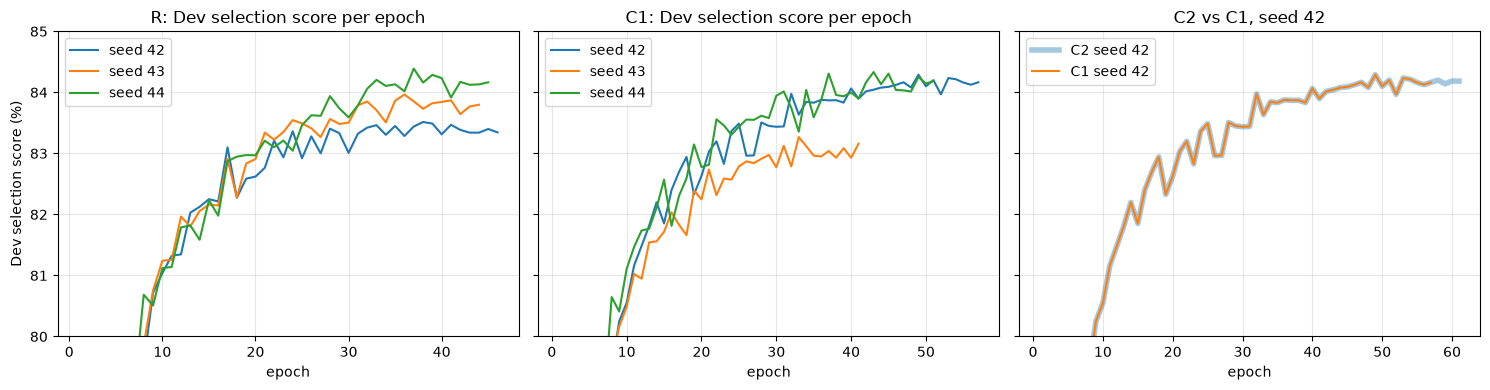

C2 repeats C1 exactly for all 57 C1 epochs: True
C2 epochs after C1 stopped: 58: 84.20 (lr 1.6e-05), 59: 84.14 (lr 7.8e-06), 60: 84.19 (lr 7.8e-06), 61: 84.18 (lr 7.8e-06)


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes[:2], ("R", "C1")):
    for run, seed in zip(CORE_RUNS[name], SEEDS):
        h = history(run)
        ax.plot([e["epoch"] for e in h], [e["selection_score"] for e in h], label=f"seed {seed}")
    ax.set_title(f"{name}: Dev selection score per epoch")
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Dev selection score (%)")
c1, c2 = history(CORE_RUNS["C1"][0]), history(CORE_RUNS["C2"][0])
axes[2].plot([e["epoch"] for e in c2], [e["selection_score"] for e in c2], label="C2 seed 42", lw=4, alpha=0.4)
axes[2].plot([e["epoch"] for e in c1], [e["selection_score"] for e in c1], label="C1 seed 42")
axes[2].set_title("C2 vs C1, seed 42"); axes[2].set_xlabel("epoch"); axes[2].grid(alpha=0.3); axes[2].legend()
for ax in axes: ax.set_ylim(80, 85)
plt.tight_layout(); plt.show()

metrics = ("train_loss", "dev_loss", "intent_accuracy_pct", "slot_micro_f1_pct", "selection_score", "learning_rate")
same = all(all(a[k] == b[k] for k in metrics) for a, b in zip(c1, c2))
print(f"C2 repeats C1 exactly for all {len(c1)} C1 epochs: {same}")
print("C2 epochs after C1 stopped:", ", ".join(
    f"{int(e['epoch'])}: {e['selection_score']:.2f} (lr {e['learning_rate']:.1e})" for e in c2[len(c1):]))
assert same


## 2. Per-class diagnostics: what C1 traded

In [4]:
analysis = json.loads(EMBEDDED["files"]["results/role_d/c_analysis.json"]["text"])
print("C1 minus R by seed, Dev (points). Computed from the saved Dev predictions by "
      "scripts/d_c_analysis.py.\n")
print(f"{'seed':<6}{'rarest quarter':>16}{'most frequent quarter':>24}{'general_quirky F1':>20}{'qa_factoid F1':>16}")
for seed in map(str, SEEDS):
    r, c = analysis["runs"]["R"][seed], analysis["runs"]["C1"][seed]
    rare = c["accuracy_by_train_frequency"]["rarest_quarter"]["dev_accuracy_pct"] - r["accuracy_by_train_frequency"]["rarest_quarter"]["dev_accuracy_pct"]
    freq = c["accuracy_by_train_frequency"]["most_frequent_quarter"]["dev_accuracy_pct"] - r["accuracy_by_train_frequency"]["most_frequent_quarter"]["dev_accuracy_pct"]
    gq = c["watched_intent_f1_pct"]["general_quirky"] - r["watched_intent_f1_pct"]["general_quirky"]
    qa = c["watched_intent_f1_pct"]["qa_factoid"] - r["watched_intent_f1_pct"]["qa_factoid"]
    print(f"{seed:<6}{rare:>+16.2f}{freq:>+24.2f}{gq:>+20.2f}{qa:>+16.2f}")
support = analysis["runs"]["R"]["42"]["accuracy_by_train_frequency"]
print(f"\nDev support: rarest quarter {support['rarest_quarter']['dev_support']}, "
      f"most frequent quarter {support['most_frequent_quarter']['dev_support']} utterances")


C1 minus R by seed, Dev (points). Computed from the saved Dev predictions by scripts/d_c_analysis.py.

seed    rarest quarter   most frequent quarter   general_quirky F1   qa_factoid F1
42               +2.75                   -1.21               -3.07           +1.62
43               +4.59                   -1.47               -7.56           -3.52
44               +1.83                   -1.38               -2.91           -2.20

Dev support: rarest quarter 109, most frequent quarter 1157 utterances


## 3. Design sensitivity sweep

Dev only; it does not change the frozen Stage 1 or Stage 2 systems. The preferred depth or width is the best 3-seed mean, unless a smaller model is within one seed SD of it. A component has a consistent gain if removing it lowers the score on all three seeds.

In [5]:
if not SWEEP_READY:
    print("Sweep runs not finished when this notebook was built; this section is filled in on rebuild.")
else:
    R = CORE_RUNS["R"]
    depth = {1: R, 2: SWEEP_RUNS["layers2"], 3: SWEEP_RUNS["layers3"]}
    width = {64: SWEEP_RUNS["hidden64"], 128: R, 256: SWEEP_RUNS["hidden256"]}
    ablation = {"full recipe": R, "no character CNN": SWEEP_RUNS["nochar"],
                "no word dropout": SWEEP_RUNS["nowd"], "neither": SWEEP_RUNS["neither"]}

    def stats(runs):
        scores = [row(r)["score"] for r in runs]
        m, sd = mean_sd(scores)
        return {"scores": scores, "mean": m, "sd": sd, "params": row(runs[0])["params"]}

    def choose(sweep, current):  # rule 2 of the sweep plan
        s = {k: stats(v) for k, v in sweep.items()}
        best = max(s, key=lambda k: s[k]["mean"])
        beaten = [k for k in s if s[k]["mean"] - s[current]["mean"] > max(s[k]["sd"], s[current]["sd"])]
        near = [k for k in s if s[best]["mean"] - s[k]["mean"] <= max(s[k]["sd"], s[best]["sd"])]
        return s, best, beaten, min(near, key=lambda k: s[k]["params"])

    def plot(s, preferred, xlabel, title, ax, log2=False):
        xs = sorted(s)
        for x in xs:
            ax.scatter([x] * 3, s[x]["scores"], color="0.65", s=18, zorder=2)
        ax.errorbar(xs, [s[x]["mean"] for x in xs], yerr=[s[x]["sd"] for x in xs], marker="o",
                    capsize=4, zorder=3, label="3-seed mean ± SD")
        ax.scatter([preferred], [s[preferred]["mean"]], s=160, facecolors="none", edgecolors="C3",
                   linewidths=2, zorder=4, label=f"preferred = {preferred}")
        if log2:
            ax.set_xscale("log", base=2)
        ax.set_xticks(xs); ax.set_xticklabels([str(x) for x in xs])
        ax.set_xlabel(xlabel); ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for label, sweep, current, ax, xlabel, log2 in (
        ("Depth (BiLSTM layers, width 128)", depth, 1, axes[0], "number of BiLSTM layers", False),
        ("Width (hidden size per direction, 1 layer)", width, 128, axes[1], "hidden size", True),
    ):
        s, best, beaten, preferred = choose(sweep, current)
        print(label)
        for k in sorted(s):
            print(f"  {k:>4}: params {s[k]['params']:>9,}  score {s[k]['mean']:.2f} (SD {s[k]['sd']:.2f})  "
                  f"seeds {', '.join(f'{x:.2f}' for x in s[k]['scores'])}")
        print(f"  best mean = {best}; current ({current}) supported: {not beaten}; preferred = {preferred}\n")
        plot(s, preferred, xlabel, f"Dev score vs {label.split(' (')[0].lower()}", ax, log2)
    axes[0].set_ylabel("Dev selection score (%)")

    print("Character CNN and word dropout (full recipe minus reduced recipe, by seed)")
    full = stats(ablation["full recipe"])
    for name, reduced in (("character CNN", "no character CNN"), ("word dropout", "no word dropout"),
                          ("both vs neither", "neither")):
        red = stats(ablation[reduced])
        diffs = [f - r for f, r in zip(full["scores"], red["scores"])]
        verdict = ("consistent gain" if all(d > 0 for d in diffs)
                   else "average gain only" if statistics.mean(diffs) > 0 else "no gain")
        print(f"  {name:<16} {', '.join(f'{d:+.2f}' for d in diffs)}  mean {statistics.mean(diffs):+.2f}  -> {verdict}")
    names = list(ablation)
    for i, seed in enumerate(SEEDS):
        axes[2].plot(range(4), [stats(ablation[n])["scores"][i] for n in names], marker="o", label=f"seed {seed}")
    axes[2].plot(range(4), [stats(ablation[n])["mean"] for n in names], marker="s", color="black", lw=2, label="mean")
    axes[2].set_xticks(range(4)); axes[2].set_xticklabels(names, fontsize=8)
    axes[2].set_title("Character CNN and word dropout, 3 seeds"); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()


Sweep runs not finished when this notebook was built; this section is filled in on rebuild.
